# KHỬ NHIỄU TIẾNG NÓI CHỮ SỐ BẰNG U-NET 2D DAE TRÊN LOG-MEL

**Đối chứng Wiener và Spectral Subtraction trên FSDD; đánh giá chi phí xử lý hướng tới ứng dụng tại biên IoT**

Notebook bám theo bản đề cương đã chỉnh sửa:

- FSDD **v1.0.10**, 3.000 bản ghi, 6 speaker, 8 kHz.
- Speaker-disjoint split 4/1/1:
  - Train: `jackson, nicolas, theo, yweweler`
  - Validation: `george`
  - Test: `lucas`
- Không VAD/crop mặc định; file dài hơn 1 giây được chia block 8.000 mẫu rồi ghép lại.
- Nhiễu **AWGN** và **Babble**, SNR `{0,5,10}` dB.
- Babble: trộn 4 luồng speech từ **MUSAN**.
- Prefix nhiễu 0,256 s (2.048 mẫu) dành cho baseline.
- STFT: `n_fft=512`, `win_length=512`, `hop_length=128`, Hann, `center=True`.
- Log-mel: 64 dải, 20–4.000 Hz, log tự nhiên; 63 frame thật + 1 cột pad.
- Min-Max chỉ tính từ train.
- U-Net 2D DAE 16–32–64–128; output tuyến tính.
- Loss: `L1 + L2`, không tính cột pad.
- Khôi phục: denormalize → exp → Mel inverse xấp xỉ NNLS → pha noisy → ISTFT.
- So sánh: Noisy, Spectral Subtraction, Wiener, U-Net.
- Chỉ số: SNR_gain, PESQ-NB, STOI, ΔPESQ, ΔSTOI.
- Có ablation bỏ skip connection và benchmark CPU.

> MUSAN chính thức khoảng 11 GB. Notebook tải trực tiếp trên Colab; lần đầu sẽ lâu.

# NHẬT KÝ CHỈNH SỬA – BẢN FIX 2026-10-05

Bản này được sinh lại từ notebook **VuMinhDuc_FSDD_UNet2D_DAE_3Seeds_DriveAutoSave(1).ipynb** và giữ nguyên protocol thí nghiệm chính. Các sửa đổi tập trung vào tốc độ, khả năng chạy lại và các lỗi đã xuất hiện khi chạy thực tế.

## Các thay đổi chính

1. **Cell 2 – cấu hình DataLoader**
   - Đặt `NUM_WORKERS = 4` cho Colab High-RAM/A100.
   - Nếu runtime gặp lỗi worker, có thể hạ về `2`.

2. **Cell 5 – MUSAN**
   - `wget` hiển thị tiến độ tải.
   - Hỗ trợ tiếp tục tải bằng `-c`.
   - Dùng `pv` để hiển thị tiến độ giải nén.
   - Chỉ giải nén khi chưa có `musan/speech`.

3. **Cell 16 – cache Log-mel train/validation**
   - Tạo Log-mel đã normalize một lần và lưu tại `/content/fsdd_denoising_full/logmel_cache_v2/`.
   - Các epoch sau chỉ đọc tensor cache, tránh lặp lại đọc WAV + tạo noise + STFT + Mel ở mỗi epoch.
   - Cache nằm ở `/content` để I/O nhanh; checkpoint/log/result vẫn lưu Drive.

4. **Cell 19 – DataLoader + checkpoint**
   - Bật `persistent_workers` khi `NUM_WORKERS > 0`.
   - Ép các scalar lưu checkpoint về kiểu Python (`float`, `int`) để giảm lỗi tương thích `torch.load` mới.

5. **Cell 24 – load checkpoint trên PyTorch 2.6+**
   - Dùng `torch.load(..., weights_only=False)` cho checkpoint do chính notebook tạo.
   - Giữ đúng class `UNet2DDAE`.

6. **Cell 36 – Noisy Mel round-trip**
   - Sửa tên hàm sai `mel_roundtrip_wave(...)` thành `mel_roundtrip(...)`.
   - Thêm kiểm tra success/failure và lỗi rõ ràng nếu toàn bộ mẫu fail.

7. **Cell 37 – clean-input distortion**
   - Sửa các tên hàm không tồn tại: dùng `mel_roundtrip`, `process_baseline`, `process_unet`.

8. **Cell 38 – skip-off evaluation**
   - Sửa `process_full_record_unet(...)` thành `process_unet(...)`.
   - Thêm kiểm tra failure và luôn duy trì cột `method` khi có kết quả.

9. **Cell 39 – bootstrap 95% CI**
   - Xử lý an toàn khi `skip_metrics_df` rỗng hoặc thiếu cột `method`.
   - Viết lại bootstrap cluster theo `clean_id`, phân tầng `digit` theo hướng vectorized NumPy để nhanh hơn đáng kể, vẫn dùng 2000 bootstrap.

10. **Multi-seed 4**
    - Tự khôi phục `TRAIN_SEEDS=[42,123,999]` và các thư mục multi-seed nếu cell cấu hình chưa được chạy sau khi runtime reset.
    - Kiểm tra rõ các hàm bắt buộc trước khi bắt đầu 6 lượt train/eval.

> Lưu ý: cache chỉ tối ưu preprocessing. `MAX_EPOCHS=100`, `BATCH_SIZE=32`, early stopping, U-Net, baseline, 3 seed và protocol test vẫn được giữ nguyên.


In [1]:
# ============================================================
# CELL 1 - CÀI THƯ VIỆN
# ============================================================
!pip -q install "librosa==0.11.0" "soundfile>=0.12.1" "pystoi>=0.4.1" \
    "pesq>=0.0.4" "psutil>=5.9" "pandas>=2.0" "scipy>=1.11" "matplotlib>=3.8"

  Preparing metadata (setup.py) ... done


In [2]:
# ============================================================
# CELL 2 - IMPORT + CẤU HÌNH
# ============================================================
import os, gc, json, math, time, random, hashlib, warnings, subprocess
from pathlib import Path

import numpy as np
import pandas as pd
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import psutil

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from pystoi import stoi
from pesq import pesq

SEED = 42
SR = 8000
BLOCK_LEN = 8000
CALIB_LEN = 2048
N_FFT = 512
WIN_LENGTH = 512
HOP_LENGTH = 128
N_MELS = 64
FMIN = 20
FMAX = 4000
LOG_EPS = 1e-8
EXPECTED_FRAMES = 63

NOISE_TYPES = ["awgn", "babble"]
SNR_LEVELS = [0, 5, 10]

SPLITS = {
    "train": ["jackson", "nicolas", "theo", "yweweler"],
    "val": ["george"],
    "test": ["lucas"],
}

BATCH_SIZE = 32
MAX_EPOCHS = 100
PATIENCE = 10
LR = 1e-3
WEIGHT_DECAY = 1e-4
ETA_MIN = 1e-6
NUM_WORKERS = 4  # Colab High-RAM/A100; nếu worker lỗi, hạ về 2

# True = chỉ chạy nhanh để debug; False = thí nghiệm chính thức.
SMOKE_TEST = False

def seed_everything(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

seed_everything()
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("librosa:", librosa.__version__)
print("DEVICE:", DEVICE)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu130
librosa: 0.11.0
DEVICE: cuda
GPU: NVIDIA A100-SXM4-80GB


In [3]:
# ============================================================
# 3. THƯ MỤC LÀM VIỆC + TỰ ĐỘNG LƯU GOOGLE DRIVE
# ============================================================
# Dataset lớn vẫn để trong /content để đọc/ghi nhanh hơn.
# Toàn bộ checkpoint, log, CSV kết quả, config, README... được
# lưu trực tiếp trên Google Drive để không mất khi Colab reset.

from google.colab import drive

# Mount Drive. Colab sẽ yêu cầu cấp quyền ở lần đầu của runtime.
drive.mount("/content/drive")

# -----------------------------
# Workspace tạm trên Colab
# -----------------------------
ROOT = Path("/content/fsdd_denoising_full")
DATA_DIR = ROOT / "data"

FSDD_DIR = DATA_DIR / "free-spoken-digit-dataset"
MUSAN_DIR = DATA_DIR / "musan"

# -----------------------------
# Workspace bền vững trên Drive
# -----------------------------
DRIVE_ROOT = Path("/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc")

ARTIFACT_DIR = DRIVE_ROOT / "artifacts"
CKPT_DIR = DRIVE_ROOT / "checkpoints"
RESULT_DIR = DRIVE_ROOT / "results"
EXPORT_DIR = DRIVE_ROOT / "export"

for p in [
    ROOT,
    DATA_DIR,
    DRIVE_ROOT,
    ARTIFACT_DIR,
    CKPT_DIR,
    RESULT_DIR,
    EXPORT_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

print("Dataset/cache tạm trên Colab :", DATA_DIR)
print("Kết quả lưu bền vững trên Drive:", DRIVE_ROOT)

Mounted at /content/drive
Dataset/cache tạm trên Colab : /content/fsdd_denoising_full/data
Kết quả lưu bền vững trên Drive: /content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc


In [4]:
# ============================================================
# 3.1. KIỂM TRA DRIVE + THÔNG TIN RESUME
# ============================================================
# Cell này giúp xác nhận Drive đã mount và hiển thị những checkpoint
# đã tồn tại. Nếu runtime bị ngắt, các file đã lưu trước đó vẫn còn.

assert DRIVE_ROOT.exists(), "Google Drive chưa mount hoặc DRIVE_ROOT không tồn tại."

existing_ckpts = sorted(CKPT_DIR.glob("*.pt"))
existing_logs = sorted(RESULT_DIR.glob("*.csv"))

print(f"Drive root: {DRIVE_ROOT}")
print(f"Checkpoint hiện có: {len(existing_ckpts)}")
for p in existing_ckpts[:10]:
    print(" -", p.name)

print(f"CSV kết quả hiện có: {len(existing_logs)}")

Drive root: /content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc
Checkpoint hiện có: 2
 - unet_main_best.pt
 - unet_skip_off_best.pt
CSV kết quả hiện có: 22


In [5]:
# ============================================================
# CELL 4 - TẢI FSDD v1.0.10 TRỰC TIẾP TRÊN COLAB
# ============================================================
# Khóa đúng tag v1.0.10 để tái lập thí nghiệm.
if not FSDD_DIR.exists():
    subprocess.run([
        "git", "clone", "--branch", "v1.0.10", "--depth", "1",
        "https://github.com/Jakobovski/free-spoken-digit-dataset.git",
        str(FSDD_DIR)
    ], check=True)

recording_dir = FSDD_DIR / "recordings"
wav_files = sorted(recording_dir.glob("*.wav"))

print("Số WAV:", len(wav_files))
assert len(wav_files) == 3000, f"Kỳ vọng 3000 file, hiện có {len(wav_files)}"

Số WAV: 3000


## MUSAN dùng cho Babble

Đề cương yêu cầu Babble từ speech của MUSAN. OpenSLR cung cấp MUSAN thành archive lớn khoảng 11 GB. Cell dưới tải trực tiếp bằng `wget -c`, vì vậy nếu Colab ngắt có thể chạy lại để tiếp tục tải.

Không thay MUSAN bằng nguồn khác một cách âm thầm vì như vậy sẽ đổi protocol.

In [6]:
# ============================================================
# CELL 5 - TẢI MUSAN TỪ OPENSLR (CÓ TIẾN ĐỘ + RESUME)
# ============================================================
DOWNLOAD_MUSAN = True
MUSAN_URL = "https://www.openslr.org/resources/17/musan.tar.gz"
MUSAN_TAR = DATA_DIR / "musan.tar.gz"
MUSAN_SPEECH_DIR = MUSAN_DIR / "speech"

if DOWNLOAD_MUSAN:
    # Nếu speech chưa tồn tại thì bảo đảm archive được tải đủ rồi giải nén.
    if not MUSAN_SPEECH_DIR.exists():
        print("Đang tải/tiếp tục tải MUSAN (~11 GB)...")
        # Không capture stdout/stderr để Colab hiển thị progress wget trực tiếp.
        subprocess.run(
            ["wget", "-c", "--show-progress", "-O", str(MUSAN_TAR), MUSAN_URL],
            check=True
        )

        print("\nCài pv để hiển thị tiến độ giải nén...")
        subprocess.run(["apt-get", "-qq", "update"], check=True)
        subprocess.run(["apt-get", "-qq", "install", "-y", "pv"], check=True)

        print("Đang giải nén MUSAN...")
        archive_size = MUSAN_TAR.stat().st_size
        pv = subprocess.Popen(
            ["pv", "-p", "-t", "-e", "-r", "-b", "-s", str(archive_size), str(MUSAN_TAR)],
            stdout=subprocess.PIPE
        )
        try:
            subprocess.run(
                ["tar", "-xzf", "-", "-C", str(DATA_DIR)],
                stdin=pv.stdout,
                check=True
            )
        finally:
            if pv.stdout is not None:
                pv.stdout.close()
            rc = pv.wait()
            if rc != 0:
                raise RuntimeError(f"pv kết thúc với mã lỗi {rc}")
    else:
        print("MUSAN speech đã tồn tại, bỏ qua download/extract:", MUSAN_SPEECH_DIR)
else:
    print("DOWNLOAD_MUSAN=False")

if DOWNLOAD_MUSAN:
    assert MUSAN_SPEECH_DIR.exists(), "Không tìm thấy thư mục musan/speech sau khi giải nén"

print("MUSAN speech dir:", MUSAN_SPEECH_DIR)


Đang tải/tiếp tục tải MUSAN (~11 GB)...

Cài pv để hiển thị tiến độ giải nén...
Đang giải nén MUSAN...
MUSAN speech dir: /content/fsdd_denoising_full/data/musan/speech


In [7]:
# ============================================================
# CELL 6 - HÀM AUDIO + HASH + METADATA
# ============================================================
def sha256_file(path, chunk_size=1024*1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()

def parse_fsdd_filename(path):
    # FSDD: {digit}_{speaker}_{index}.wav
    digit, speaker, idx = Path(path).stem.split("_")
    return int(digit), speaker, int(idx)

def split_for_speaker(speaker):
    for split_name, speakers in SPLITS.items():
        if speaker in speakers:
            return split_name
    raise ValueError(f"Speaker chưa gán split: {speaker}")

def load_audio(path, target_sr=SR):
    y, sr = sf.read(path, dtype="float32", always_2d=False)
    if y.ndim == 2:
        y = y.mean(axis=1).astype(np.float32)
    if sr != target_sr:
        y = librosa.resample(y, orig_sr=sr, target_sr=target_sr).astype(np.float32)
        sr = target_sr
    return y.astype(np.float32), sr

In [8]:
# ============================================================
# CELL 7 - TẠO manifest.csv + KIỂM TRA RÒ RỈ
# ============================================================
rows = []
for p in tqdm(wav_files, desc="Quét FSDD"):
    digit, speaker, idx = parse_fsdd_filename(p)
    info = sf.info(p)
    rows.append({
        "clean_id": p.stem,
        "path": str(p),
        "digit": digit,
        "speaker": speaker,
        "index": idx,
        "split": split_for_speaker(speaker),
        "samplerate_original": int(info.samplerate),
        "channels": int(info.channels),
        "subtype": str(info.subtype),
        "frames": int(info.frames),
        "duration_sec": float(info.duration),
        "sha256": sha256_file(p),
    })

manifest = pd.DataFrame(rows).sort_values(
    ["split", "speaker", "digit", "index"]
).reset_index(drop=True)

manifest.to_csv(ARTIFACT_DIR / "manifest.csv", index=False)
display(manifest.head())
display(manifest.groupby(["split","speaker"]).size().rename("n_files"))

speaker_sets = {
    s: set(manifest.loc[manifest["split"]==s, "speaker"].unique())
    for s in ["train","val","test"]
}
assert speaker_sets["train"].isdisjoint(speaker_sets["val"])
assert speaker_sets["train"].isdisjoint(speaker_sets["test"])
assert speaker_sets["val"].isdisjoint(speaker_sets["test"])

# Cùng SHA256 không được xuất hiện ở nhiều split.
assert (manifest.groupby("sha256")["split"].nunique() <= 1).all()

with open(ARTIFACT_DIR / "splits.json", "w", encoding="utf-8") as f:
    json.dump({"seed": SEED, **SPLITS}, f, indent=2, ensure_ascii=False)

Quét FSDD:   0%|          | 0/3000 [00:00<?, ?it/s]

,clean_id,path,digit,speaker,index,split,samplerate_original,channels,subtype,frames,duration_sec,sha256
0,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,0,lucas,0,test,8000,1,PCM_16,5083,0.635375,1d942e79c200ae1f84618314f2669d9c154718276b38cc...
1,0_lucas_1,/content/fsdd_denoising_full/data/free-spoken-...,0,lucas,1,test,8000,1,PCM_16,5475,0.684375,9c2bb9ff24714b163c681d82c4ed99339c9408e9a126c0...
2,0_lucas_2,/content/fsdd_denoising_full/data/free-spoken-...,0,lucas,2,test,8000,1,PCM_16,5870,0.733750,98a9869e199ee41a7bd1435158d6844633f0e1e05565a4...
3,0_lucas_3,/content/fsdd_denoising_full/data/free-spoken-...,0,lucas,3,test,8000,1,PCM_16,4455,0.556875,4fadd8fa097688679d1971a97ee649f40822e3262f2c4c...
4,0_lucas_4,/content/fsdd_denoising_full/data/free-spoken-...,0,lucas,4,test,8000,1,PCM_16,4072,0.509000,50b70103863389972001597d1136a8c7eea17fd7d98c72...


split  speaker 
test   lucas       500
train  jackson     500
       nicolas     500
       theo        500
       yweweler    500
val    george      500
Name: n_files, dtype: int64

Sample rate:


,count
samplerate_original,
8000,3000


Channels:


,count
channels,
1,3000


Subtype:


,count
subtype,
PCM_16,3000


Duration:


,duration_sec
count,3000.000000
mean,0.437434
std,0.147643
min,0.143500
1%,0.192621
5%,0.245981
25%,0.342344
50%,0.419813
75%,0.510281
95%,0.662419


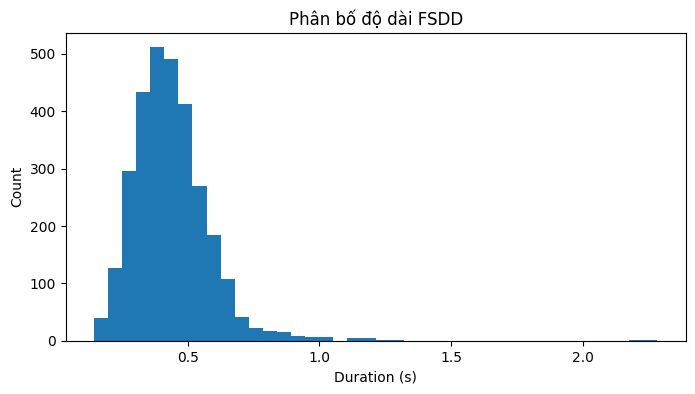

File > 1 giây: 20


In [9]:
# ============================================================
# CELL 8 - EDA FSDD
# ============================================================
print("Sample rate:")
display(manifest["samplerate_original"].value_counts().sort_index())

print("Channels:")
display(manifest["channels"].value_counts().sort_index())

print("Subtype:")
display(manifest["subtype"].value_counts())

print("Duration:")
display(manifest["duration_sec"].describe(
    percentiles=[.01,.05,.25,.5,.75,.95,.99]
))

plt.figure(figsize=(8,4))
plt.hist(manifest["duration_sec"], bins=40)
plt.xlabel("Duration (s)")
plt.ylabel("Count")
plt.title("Phân bố độ dài FSDD")
plt.show()

print("File > 1 giây:", int((manifest["frames"] > BLOCK_LEN).sum()))

In [10]:
# ============================================================
# CELL 9 - CHIA NGUỒN SPEECH MUSAN THEO SPLIT
# ============================================================
if not MUSAN_SPEECH_DIR.exists():
    raise RuntimeError("Chưa có MUSAN. Hãy chạy CELL 5.")

musan_speech = sorted(MUSAN_SPEECH_DIR.rglob("*.wav"))
assert len(musan_speech) > 0
print("MUSAN speech WAV:", len(musan_speech))

rng = np.random.default_rng(SEED)
idx = np.arange(len(musan_speech))
rng.shuffle(idx)

n = len(idx)
n_train = int(0.70*n)
n_val = int(0.15*n)

idx_split = {
    "train": idx[:n_train],
    "val": idx[n_train:n_train+n_val],
    "test": idx[n_train+n_val:],
}
noise_files = {
    split: [musan_speech[i] for i in ids]
    for split, ids in idx_split.items()
}

noise_rows = []
for split, files in noise_files.items():
    for p in files:
        noise_rows.append({
            "noise_file": str(p),
            "source_id": str(p.relative_to(MUSAN_SPEECH_DIR)),
            "split": split
        })

pd.DataFrame(noise_rows).to_csv(
    ARTIFACT_DIR / "noise_manifest.csv", index=False
)

for s in noise_files:
    print(s, len(noise_files[s]))

MUSAN speech WAV: 426
train 298
val 63
test 65


In [11]:
# ============================================================
# CELL 10 - TẠO BABBLE 4 LUỒNG
# ============================================================
_AUDIO_CACHE = {}

def rms(x, eps=1e-12):
    return float(np.sqrt(np.mean(np.square(x), dtype=np.float64) + eps))

def load_noise_resampled(path):
    key = str(path)
    if key in _AUDIO_CACHE:
        return _AUDIO_CACHE[key]

    y, sr = sf.read(path, dtype="float32", always_2d=False)
    if y.ndim == 2:
        y = y.mean(axis=1).astype(np.float32)
    if sr != SR:
        y = librosa.resample(y, orig_sr=sr, target_sr=SR).astype(np.float32)

    if len(_AUDIO_CACHE) < 32:
        _AUDIO_CACHE[key] = y
    return y

def choose_segment(x, length, rng):
    if len(x) == 0:
        raise ValueError("Noise source rỗng")
    if len(x) < length:
        x = np.tile(x, int(np.ceil(length/len(x))))
    max_start = len(x) - length
    start = 0 if max_start <= 0 else int(rng.integers(0, max_start+1))
    return x[start:start+length].astype(np.float32), start

def make_babble_segment(split, total_len, rng, n_streams=4):
    pool = noise_files[split]
    sel = rng.choice(len(pool), size=n_streams, replace=False)

    streams, source_ids, offsets = [], [], []
    for i in sel:
        p = pool[int(i)]
        x = load_noise_resampled(p)
        seg, start = choose_segment(x, total_len, rng)

        # RMS normalize từng luồng trước khi cộng.
        r = rms(seg)
        if r < 1e-8:
            seg, start = choose_segment(x, total_len, rng)
            r = rms(seg)

        streams.append(seg / max(r, 1e-8))
        source_ids.append(str(p.relative_to(MUSAN_SPEECH_DIR)))
        offsets.append(int(start))

    babble = np.mean(np.stack(streams), axis=0).astype(np.float32)
    return babble, source_ids, offsets

In [12]:
# ============================================================
# CELL 11 - PHỐI TRỘN THEO SNR + PREFIX 0.256s
# ============================================================
def scale_noise_for_snr(clean, noise, snr_db):
    Es = float(np.sum(clean.astype(np.float64)**2))
    Ev = float(np.sum(noise.astype(np.float64)**2))
    if Es <= 1e-12 or Ev <= 1e-12:
        raise ValueError("Năng lượng clean/noise quá nhỏ")
    alpha = math.sqrt(Es / (Ev * 10**(snr_db/10)))
    return (alpha*noise).astype(np.float32), float(alpha)

def measured_snr(clean, noisy):
    n = noisy-clean
    Es = np.sum(clean.astype(np.float64)**2)
    En = np.sum(n.astype(np.float64)**2)
    return float(10*np.log10((Es+1e-12)/(En+1e-12)))

def create_noisy_record(clean, split, noise_type, snr_db, seed):
    rng = np.random.default_rng(seed)
    L = len(clean)
    total_len = CALIB_LEN + L

    if noise_type == "awgn":
        raw = rng.standard_normal(total_len).astype(np.float32)
        source_ids, offsets = ["awgn_rng"], [0]
    elif noise_type == "babble":
        raw, source_ids, offsets = make_babble_segment(
            split, total_len, rng, n_streams=4
        )
    else:
        raise ValueError(noise_type)

    raw_prefix = raw[:CALIB_LEN]
    raw_speech = raw[CALIB_LEN:]

    scaled_speech, alpha = scale_noise_for_snr(
        clean, raw_speech, snr_db
    )
    prefix = (alpha*raw_prefix).astype(np.float32)
    noisy = (clean + scaled_speech).astype(np.float32)

    actual = measured_snr(clean, noisy)

    return {
        "clean": clean,
        "noisy": noisy,
        "noise_prefix": prefix,
        "alpha": alpha,
        "snr_actual": actual,
        "source_ids": source_ids,
        "offsets": offsets,
    }

# Software test SNR.
c0, _ = load_audio(manifest.iloc[0]["path"])
m0 = create_noisy_record(c0, manifest.iloc[0]["split"], "awgn", 5, 123)
print("SNR actual:", m0["snr_actual"])
assert abs(m0["snr_actual"]-5) <= 0.1

SNR actual: 5.000000201392528


In [13]:
# ============================================================
# CELL 12 - BLOCKING 1 GIÂY, KHÔNG CROP DỮ LIỆU
# ============================================================
def split_into_blocks(x, block_len=BLOCK_LEN):
    x = np.asarray(x, dtype=np.float32)
    L = len(x)
    blocks = []

    for start in range(0, max(L,1), block_len):
        b = x[start:start+block_len]
        if len(b) < block_len:
            b = np.pad(b, (0, block_len-len(b)))
        blocks.append(b.astype(np.float32))

    return blocks, L

def merge_blocks(blocks, original_length):
    return np.concatenate(blocks)[:original_length].astype(np.float32)

In [14]:
# ============================================================
# CELL 13 - STFT / LOG-MEL
# ============================================================
MEL_BASIS = librosa.filters.mel(
    sr=SR, n_fft=N_FFT, n_mels=N_MELS,
    fmin=FMIN, fmax=FMAX,
    htk=False, norm="slaney"
).astype(np.float32)

def stft_complex(x):
    return librosa.stft(
        x, n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        window="hann",
        center=True,
        pad_mode="constant"
    )

def istft_complex(S, length=BLOCK_LEN):
    return librosa.istft(
        S,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        window="hann",
        center=True,
        length=length
    ).astype(np.float32)

def logmel_from_wave(x):
    S = stft_complex(x)
    power = np.abs(S)**2
    mel_power = MEL_BASIS @ power
    L = np.log(mel_power + LOG_EPS).astype(np.float32)
    assert L.shape == (64,63), L.shape
    return L

# Test STFT round-trip.
b0 = split_into_blocks(c0)[0][0]
r0 = istft_complex(stft_complex(b0), length=BLOCK_LEN)
rel = np.linalg.norm(b0-r0)/(np.linalg.norm(b0)+1e-12)
print("STFT->ISTFT relative error:", rel)

STFT->ISTFT relative error: 7.934864e-08


In [15]:
# ============================================================
# CELL 14 - KHÓA DANH SÁCH CẶP DỮ LIỆU
# ============================================================
def stable_seed(*parts, base_seed=SEED):
    text = "|".join(map(str, parts)) + f"|{base_seed}"
    return int(hashlib.sha256(text.encode()).hexdigest()[:8], 16)

base_manifest = manifest
if SMOKE_TEST:
    base_manifest = pd.concat([
        manifest[manifest["split"]=="train"].head(30),
        manifest[manifest["split"]=="val"].head(10),
        manifest[manifest["split"]=="test"].head(10),
    ], ignore_index=True)

pair_rows = []
for _, row in base_manifest.iterrows():
    for nt in NOISE_TYPES:
        for snr in SNR_LEVELS:
            pair_rows.append({
                "clean_id": row["clean_id"],
                "clean_path": row["path"],
                "speaker": row["speaker"],
                "digit": int(row["digit"]),
                "split": row["split"],
                "noise_type": nt,
                "snr_target": snr,
                "seed": stable_seed(row["clean_id"], nt, snr),
            })

pairs_df = pd.DataFrame(pair_rows)
pairs_df.to_csv(ARTIFACT_DIR/"pairs_all.csv", index=False)
pairs_df[pairs_df["split"].isin(["val","test"])].to_csv(
    ARTIFACT_DIR/"pairs_val_test.csv", index=False
)

display(pairs_df.groupby(
    ["split","noise_type","snr_target"]
).size())

split  noise_type  snr_target
test   awgn        0              500
                   5              500
                   10             500
       babble      0              500
                   5              500
                   10             500
train  awgn        0             2000
                   5             2000
                   10            2000
       babble      0             2000
                   5             2000
                   10            2000
val    awgn        0              500
                   5              500
                   10             500
       babble      0              500
                   5              500
                   10             500
dtype: int64

In [16]:
# ============================================================
# CELL 15 - MIN-MAX CHỈ TỪ TRAIN
# ============================================================
norm_path = ARTIFACT_DIR/"norm_stats.npz"

if norm_path.exists():
    z = np.load(norm_path)
    NORM_MIN = float(z["a"])
    NORM_MAX = float(z["b"])
else:
    a, b = np.inf, -np.inf
    train_pairs = pairs_df[pairs_df["split"]=="train"]

    for _, row in tqdm(
        train_pairs.iterrows(),
        total=len(train_pairs),
        desc="Compute train Min-Max"
    ):
        clean, _ = load_audio(row["clean_path"])
        mix = create_noisy_record(
            clean, "train", row["noise_type"],
            float(row["snr_target"]), int(row["seed"])
        )

        cb, _ = split_into_blocks(mix["clean"])
        nb, _ = split_into_blocks(mix["noisy"])

        for cblk, nblk in zip(cb, nb):
            Lc = logmel_from_wave(cblk)
            Ln = logmel_from_wave(nblk)
            a = min(a, float(Lc.min()), float(Ln.min()))
            b = max(b, float(Lc.max()), float(Ln.max()))

    assert np.isfinite(a) and np.isfinite(b) and b > a
    NORM_MIN, NORM_MAX = a, b
    np.savez(norm_path, a=a, b=b)

print("Min-Max:", NORM_MIN, NORM_MAX)

def normalize_logmel(L):
    return ((L-NORM_MIN)/(NORM_MAX-NORM_MIN)).astype(np.float32)

def denormalize_logmel(X):
    return (X*(NORM_MAX-NORM_MIN)+NORM_MIN).astype(np.float32)

def pad_time_column(X):
    assert X.shape == (64,63)
    return np.pad(X, ((0,0),(0,1))).astype(np.float32)

def unpad_time_column(X):
    assert X.shape == (64,64)
    return X[:,:63].astype(np.float32)

Min-Max: -18.42068099975586 5.121213912963867


In [17]:
# ============================================================
# CELL 16 - CACHE LOG-MEL + PYTORCH DATASET
# ============================================================
# Cache ở /content để đọc nhanh khi train. Output/checkpoint vẫn nằm trên Drive.
CACHE_VERSION = "v2_fixed_pairs_norm_logmel_64x64"
CACHE_ROOT = ROOT / "logmel_cache_v2"
TRAIN_CACHE_DIR = CACHE_ROOT / "train"
VAL_CACHE_DIR = CACHE_ROOT / "val"

TRAIN_CACHE_DIR.mkdir(parents=True, exist_ok=True)
VAL_CACHE_DIR.mkdir(parents=True, exist_ok=True)


def build_logmel_cache(pairs_subset, cache_dir, split_name):
    pairs = pairs_subset.reset_index(drop=True).copy()
    items = []

    # 1) Xác định toàn bộ chunk.
    for pair_idx, row in tqdm(
        pairs.iterrows(), total=len(pairs), desc=f"Scan {split_name}"
    ):
        clean, _ = load_audio(row["clean_path"])
        n_blocks = max(1, math.ceil(len(clean) / BLOCK_LEN))
        for block_idx in range(n_blocks):
            items.append((pair_idx, block_idx))

    print(f"{split_name}: {len(pairs)} pairs -> {len(items)} chunks")
    index_rows = []

    # 2) Tính feature đúng pipeline cũ và lưu một lần.
    for cache_idx, (pair_idx, block_idx) in enumerate(
        tqdm(items, desc=f"Cache {split_name}")
    ):
        row = pairs.iloc[pair_idx]
        cache_file = cache_dir / f"{cache_idx:07d}.npz"

        need_build = True
        if cache_file.exists():
            try:
                with np.load(cache_file) as z:
                    need_build = not (
                        z["x"].shape == (64, 64) and
                        z["target"].shape == (64, 64)
                    )
            except Exception:
                need_build = True

        if need_build:
            clean, _ = load_audio(row["clean_path"])
            mix = create_noisy_record(
                clean,
                row["split"],
                row["noise_type"],
                float(row["snr_target"]),
                int(row["seed"])
            )

            cb, _ = split_into_blocks(mix["clean"])
            nb, _ = split_into_blocks(mix["noisy"])

            Xn = pad_time_column(
                normalize_logmel(logmel_from_wave(nb[block_idx]))
            ).astype(np.float32)
            Xc = pad_time_column(
                normalize_logmel(logmel_from_wave(cb[block_idx]))
            ).astype(np.float32)

            # File nhỏ, không nén để giảm CPU khi đọc trong DataLoader.
            np.savez(cache_file, x=Xn, target=Xc)

        index_rows.append({
            "cache_file": str(cache_file),
            "clean_id": row["clean_id"],
            "block_idx": int(block_idx),
            "noise_type": row["noise_type"],
            "snr_target": float(row["snr_target"]),
            "seed": int(row["seed"]),
        })

    index_df = pd.DataFrame(index_rows)
    index_df.to_csv(cache_dir / "index.csv", index=False)
    return index_df


train_pairs_cache = pairs_df[pairs_df["split"] == "train"].reset_index(drop=True)
val_pairs_cache = pairs_df[pairs_df["split"] == "val"].reset_index(drop=True)

train_cache_index = build_logmel_cache(
    train_pairs_cache, TRAIN_CACHE_DIR, "train"
)
val_cache_index = build_logmel_cache(
    val_pairs_cache, VAL_CACHE_DIR, "val"
)


class CachedDenoisingDataset(Dataset):
    def __init__(self, cache_index):
        self.index = cache_index.reset_index(drop=True).copy()

    def __len__(self):
        return len(self.index)

    def __getitem__(self, idx):
        row = self.index.iloc[idx]
        with np.load(row["cache_file"]) as z:
            Xn = z["x"].astype(np.float32, copy=False)
            Xc = z["target"].astype(np.float32, copy=False)

        return {
            "x": torch.from_numpy(Xn[None]),
            "target": torch.from_numpy(Xc[None]),
            "clean_id": row["clean_id"],
            "block_idx": int(row["block_idx"]),
        }


train_ds = CachedDenoisingDataset(train_cache_index)
val_ds = CachedDenoisingDataset(val_cache_index)

print("CACHE_VERSION:", CACHE_VERSION)
print("CACHE_ROOT:", CACHE_ROOT)
print("Train cached chunks:", len(train_ds))
print("Val cached chunks:", len(val_ds))

sample = train_ds[0]
print("Input shape :", sample["x"].shape)
print("Target shape:", sample["target"].shape)
assert sample["x"].shape == (1, 64, 64)
assert sample["target"].shape == (1, 64, 64)
print("CACHE DATASET OK")


Scan train:   0%|          | 0/12000 [00:00<?, ?it/s]

train: 12000 pairs -> 12036 chunks


Cache train:   0%|          | 0/12036 [00:00<?, ?it/s]

Scan val:   0%|          | 0/3000 [00:00<?, ?it/s]

val: 3000 pairs -> 3000 chunks


Cache val:   0%|          | 0/3000 [00:00<?, ?it/s]

CACHE_VERSION: v2_fixed_pairs_norm_logmel_64x64
CACHE_ROOT: /content/fsdd_denoising_full/logmel_cache_v2
Train cached chunks: 12036
Val cached chunks: 3000
Input shape : torch.Size([1, 64, 64])
Target shape: torch.Size([1, 64, 64])
CACHE DATASET OK


In [18]:
# ============================================================
# CELL 17 - U-NET 2D DAE 16-32-64-128
# ============================================================
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=True),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=True),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)

class UNet2DDAE(nn.Module):
    def __init__(self, use_skip=True):
        super().__init__()
        self.use_skip = use_skip

        self.e1 = DoubleConv(1,16)
        self.p1 = nn.MaxPool2d(2)
        self.e2 = DoubleConv(16,32)
        self.p2 = nn.MaxPool2d(2)
        self.e3 = DoubleConv(32,64)
        self.p3 = nn.MaxPool2d(2)
        self.b = DoubleConv(64,128)

        self.u3 = nn.Upsample(scale_factor=2, mode="nearest")
        self.r3 = nn.Conv2d(128,64,1)
        self.d3 = DoubleConv(128,64)

        self.u2 = nn.Upsample(scale_factor=2, mode="nearest")
        self.r2 = nn.Conv2d(64,32,1)
        self.d2 = DoubleConv(64,32)

        self.u1 = nn.Upsample(scale_factor=2, mode="nearest")
        self.r1 = nn.Conv2d(32,16,1)
        self.d1 = DoubleConv(32,16)

        self.out = nn.Conv2d(16,1,1)

    def sk(self, x):
        return x if self.use_skip else torch.zeros_like(x)

    def forward(self, x):
        e1 = self.e1(x)
        e2 = self.e2(self.p1(e1))
        e3 = self.e3(self.p2(e2))
        b = self.b(self.p3(e3))

        d3 = self.r3(self.u3(b))
        d3 = self.d3(torch.cat([d3, self.sk(e3)], dim=1))

        d2 = self.r2(self.u2(d3))
        d2 = self.d2(torch.cat([d2, self.sk(e2)], dim=1))

        d1 = self.r1(self.u1(d2))
        d1 = self.d1(torch.cat([d1, self.sk(e1)], dim=1))

        return self.out(d1)

model_check = UNet2DDAE()
n_params = sum(p.numel() for p in model_check.parameters())
print("Parameters:", f"{n_params:,}")
print("FP32 MB:", n_params*4/1e6)

with torch.no_grad():
    out_check = model_check(torch.randn(2,1,64,64))
print(out_check.shape)

Parameters: 449,489
FP32 MB: 1.797956
torch.Size([2, 1, 64, 64])


In [19]:
# ============================================================
# CELL 18 - LOSS L1 + L2, BỎ CỘT PAD
# ============================================================
def masked_hybrid_loss(pred, target, lambda_l1=1.0, lambda_l2=1.0):
    pv = pred[..., :EXPECTED_FRAMES]
    tv = target[..., :EXPECTED_FRAMES]
    diff = pv-tv

    l1 = diff.abs().mean()
    l2 = (diff**2).mean()
    total = lambda_l1*l1 + lambda_l2*l2
    return total, l1.detach(), l2.detach()

In [20]:
# ============================================================
# CELL 19 - TRAIN + EARLY STOPPING
# ============================================================
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)
val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=NUM_WORKERS,
    pin_memory=torch.cuda.is_available(),
    persistent_workers=(NUM_WORKERS > 0),
)

def run_epoch(model, loader, optimizer=None, l1w=1.0, l2w=1.0):
    training = optimizer is not None
    model.train(training)

    totals, l1s, l2s = [], [], []
    for batch in tqdm(loader, leave=False):
        x = batch["x"].to(DEVICE)
        target = batch["target"].to(DEVICE)

        if training:
            optimizer.zero_grad(set_to_none=True)

        pred = model(x)
        loss, l1, l2 = masked_hybrid_loss(pred, target, l1w, l2w)

        if training:
            loss.backward()
            optimizer.step()

        totals.append(float(loss.detach().cpu()))
        l1s.append(float(l1.cpu()))
        l2s.append(float(l2.cpu()))

    return {
        "loss": np.mean(totals),
        "l1": np.mean(l1s),
        "l2": np.mean(l2s)
    }

def train_model(use_skip=True, l1w=1.0, l2w=1.0, run_name="unet_main"):
    seed_everything(SEED)

    model = UNet2DDAE(use_skip=use_skip).to(DEVICE)
    opt = torch.optim.AdamW(
        model.parameters(), lr=LR,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9,0.999)
    )
    sch = torch.optim.lr_scheduler.CosineAnnealingLR(
        opt, T_max=MAX_EPOCHS, eta_min=ETA_MIN
    )

    best_val = np.inf
    wait = 0
    hist = []
    ckpt = CKPT_DIR/f"{run_name}_best.pt"
    n_epochs = 2 if SMOKE_TEST else MAX_EPOCHS

    for epoch in range(1,n_epochs+1):
        tr = run_epoch(model, train_loader, opt, l1w, l2w)

        with torch.no_grad():
            va = run_epoch(model, val_loader, None, l1w, l2w)

        sch.step()

        row = {
            "epoch": int(epoch),
            "lr": opt.param_groups[0]["lr"],
            "train_loss": tr["loss"],
            "train_l1": tr["l1"],
            "train_l2": tr["l2"],
            "val_loss": va["loss"],
            "val_l1": va["l1"],
            "val_l2": va["l2"],
        }
        hist.append(row)
        print(f"{run_name} | epoch={epoch:03d} | train={tr['loss']:.6f} | val={va['loss']:.6f}")

        if va["loss"] < best_val:
            best_val = va["loss"]
            wait = 0
            torch.save({
                "model_state_dict": model.state_dict(),
                "use_skip": use_skip,
                "l1w": l1w,
                "l2w": l2w,
                "norm_min": float(NORM_MIN),
                "norm_max": float(NORM_MAX),
                "epoch": int(epoch),
                "val_loss": float(best_val),
                "seed": int(SEED),
            }, ckpt)
        else:
            wait += 1

        if wait >= PATIENCE:
            print("Early stopping")
            break

    hist = pd.DataFrame(hist)
    hist.to_csv(RESULT_DIR/f"{run_name}_history.csv", index=False)
    return ckpt, hist

MAIN_CKPT, main_history = train_model(
    use_skip=True, l1w=1.0, l2w=1.0, run_name="unet_main"
)
display(main_history.tail())

  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

unet_main | epoch=001 | train=0.043517 | val=0.042871


  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

...

unet_main | epoch=014 | train=0.015798 | val=0.034961


  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

unet_main | epoch=015 | train=0.015635 | val=0.036895
Early stopping


,epoch,lr,train_loss,train_l1,train_l2,val_loss,val_l1,val_l2
10,11,0.000970,0.016816,0.015700,0.001116,0.037220,0.032848,0.004372
11,12,0.000965,0.016646,0.015555,0.001091,0.034900,0.031030,0.003870
12,13,0.000959,0.016092,0.015062,0.001030,0.035564,0.031636,0.003928
13,14,0.000952,0.015798,0.014805,0.000994,0.034961,0.031124,0.003837
14,15,0.000946,0.015635,0.014667,0.000968,0.036895,0.032700,0.004195


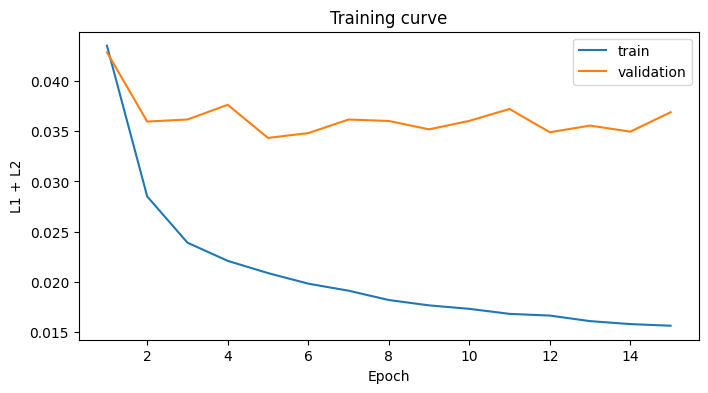

In [21]:
# ============================================================
# CELL 20 - ĐƯỜNG CONG TRAIN
# ============================================================
plt.figure(figsize=(8,4))
plt.plot(main_history["epoch"], main_history["train_loss"], label="train")
plt.plot(main_history["epoch"], main_history["val_loss"], label="validation")
plt.xlabel("Epoch")
plt.ylabel("L1 + L2")
plt.title("Training curve")
plt.legend()
plt.show()

In [22]:
# ============================================================
# CELL 21 - BASELINE: NOISE PSD + SPECTRAL SUBTRACTION + WIENER
# ============================================================
def estimate_noise_psd(prefix):
    N = librosa.stft(
        prefix, n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=WIN_LENGTH,
        window="hann",
        center=False
    )
    return np.mean(np.abs(N)**2, axis=1).astype(np.float32)

# Prefix 2048 mẫu -> 13 frame calibration.
assert librosa.stft(
    np.zeros(CALIB_LEN, dtype=np.float32),
    n_fft=N_FFT, hop_length=HOP_LENGTH,
    win_length=WIN_LENGTH, center=False
).shape[1] == 13

def spectral_subtraction_block(x, noise_psd, alpha_ss=1.0, beta_ss=0.01):
    Y = stft_complex(x)
    Yp = np.abs(Y)**2
    Ph = np.maximum(
        Yp-alpha_ss*noise_psd[:,None],
        beta_ss*Yp
    )
    Sh = np.sqrt(np.maximum(Ph,0))*np.exp(1j*np.angle(Y))
    return istft_complex(Sh, length=BLOCK_LEN)

def wiener_dd_block(x, noise_psd, alpha_dd=0.95, eps=1e-8):
    Y = stft_complex(x)
    Yp = np.abs(Y)**2
    gamma = Yp/(noise_psd[:,None]+eps)
    xi = np.zeros_like(gamma, dtype=np.float32)
    Sh = np.zeros_like(Y, dtype=np.complex64)

    xi[:,0] = np.maximum(gamma[:,0]-1,0)
    prev_power = np.zeros(Y.shape[0], dtype=np.float32)

    for t in range(Y.shape[1]):
        if t > 0:
            xi[:,t] = (
                alpha_dd*prev_power/(noise_psd+eps)
                + (1-alpha_dd)*np.maximum(gamma[:,t]-1,0)
            )
        G = xi[:,t]/(1+xi[:,t])
        Sh[:,t] = G*Y[:,t]
        prev_power = np.abs(Sh[:,t])**2

    return istft_complex(Sh, length=BLOCK_LEN)

def process_baseline(noisy, prefix, method, **kwargs):
    blocks, L = split_into_blocks(noisy)
    psd = estimate_noise_psd(prefix)
    outs = []

    for b in blocks:
        if method == "ss":
            outs.append(spectral_subtraction_block(b, psd, **kwargs))
        elif method == "wiener":
            outs.append(wiener_dd_block(b, psd, **kwargs))
        else:
            raise ValueError(method)

    return merge_blocks(outs, L)

In [23]:
# ============================================================
# CELL 22 - METRICS
# ============================================================
def snr_db(clean, estimate, eps=1e-12):
    clean = clean.astype(np.float64)
    estimate = estimate.astype(np.float64)
    Es = np.sum(clean**2)
    Ee = np.sum((clean-estimate)**2)
    if Ee <= eps:
        return np.inf
    return float(10*np.log10((Es+eps)/(Ee+eps)))

def safe_pesq(clean, estimate):
    try:
        score = pesq(SR, clean.astype(np.float32), estimate.astype(np.float32), "nb")
        return (float(score), "") if np.isfinite(score) else (np.nan, "non_finite")
    except Exception as e:
        return np.nan, f"{type(e).__name__}: {e}"

def safe_stoi(clean, estimate):
    try:
        with warnings.catch_warnings(record=True) as ws:
            warnings.simplefilter("always")
            score = stoi(clean, estimate, SR, extended=False)

        # Nếu pystoi cảnh báo do utterance quá ngắn, không đưa giá trị lỗi vào mean.
        if ws:
            return np.nan, " | ".join(str(w.message) for w in ws)

        return (float(score), "") if np.isfinite(score) else (np.nan, "non_finite")
    except Exception as e:
        return np.nan, f"{type(e).__name__}: {e}"

def evaluate_waveform(clean, noisy, enhanced):
    L = len(clean)
    noisy = noisy[:L]
    enhanced = enhanced[:L]

    si = snr_db(clean, noisy)
    so = snr_db(clean, enhanced)

    pn, _ = safe_pesq(clean, noisy)
    pe, pe_err = safe_pesq(clean, enhanced)

    sn, _ = safe_stoi(clean, noisy)
    se, se_err = safe_stoi(clean, enhanced)

    return {
        "snr_in": si,
        "snr_out": so,
        "snr_gain": so-si,
        "pesq_noisy": pn,
        "pesq": pe,
        "delta_pesq": pe-pn if np.isfinite(pe) and np.isfinite(pn) else np.nan,
        "stoi_noisy": sn,
        "stoi": se,
        "delta_stoi": se-sn if np.isfinite(se) and np.isfinite(sn) else np.nan,
        "pesq_error": pe_err,
        "stoi_error": se_err,
    }

In [24]:
# ============================================================
# CELL 23 - TUNE BASELINE CHỈ TRÊN VALIDATION
# ============================================================
SS_ALPHA = [1.0,1.5,2.0]
SS_BETA = [0.01,0.03,0.05]
W_ALPHA = [0.90,0.95,0.98]

val_pairs = pairs_df[pairs_df["split"]=="val"].reset_index(drop=True)

def tune_ss():
    rows = []
    for a in SS_ALPHA:
        for b in SS_BETA:
            gains = []
            d = val_pairs.head(12) if SMOKE_TEST else val_pairs

            for _, row in tqdm(d.iterrows(), total=len(d), leave=False):
                c, _ = load_audio(row["clean_path"])
                m = create_noisy_record(
                    c, "val", row["noise_type"],
                    float(row["snr_target"]), int(row["seed"])
                )
                o = process_baseline(
                    m["noisy"], m["noise_prefix"], "ss",
                    alpha_ss=a, beta_ss=b
                )
                gains.append(snr_db(c,o)-snr_db(c,m["noisy"]))

            rows.append({"alpha_ss":a, "beta_ss":b, "mean_snr_gain":np.mean(gains)})

    df = pd.DataFrame(rows).sort_values(
        ["mean_snr_gain","alpha_ss","beta_ss"],
        ascending=[False,True,True]
    )
    return df.iloc[0].to_dict(), df

def tune_wiener():
    rows = []
    for a in W_ALPHA:
        gains = []
        d = val_pairs.head(12) if SMOKE_TEST else val_pairs

        for _, row in tqdm(d.iterrows(), total=len(d), leave=False):
            c, _ = load_audio(row["clean_path"])
            m = create_noisy_record(
                c, "val", row["noise_type"],
                float(row["snr_target"]), int(row["seed"])
            )
            o = process_baseline(
                m["noisy"], m["noise_prefix"], "wiener",
                alpha_dd=a
            )
            gains.append(snr_db(c,o)-snr_db(c,m["noisy"]))

        rows.append({"alpha_dd":a, "mean_snr_gain":np.mean(gains)})

    df = pd.DataFrame(rows).sort_values(
        ["mean_snr_gain","alpha_dd"],
        ascending=[False,True]
    )
    return df.iloc[0].to_dict(), df

best_ss, ss_tuning = tune_ss()
best_w, w_tuning = tune_wiener()

ss_tuning.to_csv(RESULT_DIR/"ss_validation_tuning.csv", index=False)
w_tuning.to_csv(RESULT_DIR/"wiener_validation_tuning.csv", index=False)

print("Best SS:", best_ss)
print("Best Wiener:", best_w)

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

...

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

  0%|          | 0/3000 [00:00<?, ?it/s]

Best SS: {'alpha_ss': 2.0, 'beta_ss': 0.01, 'mean_snr_gain': 3.875095295860035}
Best Wiener: {'alpha_dd': 0.9, 'mean_snr_gain': 4.576081597930471}


In [25]:
# ============================================================
# CELL 24 - U-NET: INVERSE MEL + NOISY PHASE
# ============================================================
def load_trained_model(path):
    # Checkpoint này do chính notebook tạo, vì vậy có thể cho phép full pickle.
    # PyTorch 2.6+ mặc định weights_only=True nên checkpoint chứa scalar NumPy có thể lỗi.
    ckpt = torch.load(path, map_location=DEVICE, weights_only=False)
    model = UNet2DDAE(use_skip=bool(ckpt["use_skip"])).to(DEVICE)
    model.load_state_dict(ckpt["model_state_dict"])
    model.eval()
    return model

main_model = load_trained_model(MAIN_CKPT)

def predicted_logmel_to_wave(pred_x64, noisy_block):
    # Bỏ cột pad.
    X63 = unpad_time_column(pred_x64)

    # Giải chuẩn hóa + nghịch đảo log.
    Lhat = denormalize_logmel(X63)
    mel_power = np.maximum(np.exp(Lhat)-LOG_EPS, 0).astype(np.float32)

    # librosa mel_to_stft(power=2) trả về magnitude STFT xấp xỉ.
    # Không sqrt thêm lần nữa.
    mag = librosa.feature.inverse.mel_to_stft(
        M=mel_power,
        sr=SR,
        n_fft=N_FFT,
        power=2.0,
        fmin=FMIN,
        fmax=FMAX,
        htk=False,
        norm="slaney"
    )

    Y = stft_complex(noisy_block)
    Sh = mag * np.exp(1j*np.angle(Y))
    return istft_complex(Sh, length=BLOCK_LEN)

@torch.no_grad()
def process_unet(noisy, model):
    blocks, L = split_into_blocks(noisy)
    outs = []

    for b in blocks:
        X = pad_time_column(
            normalize_logmel(logmel_from_wave(b))
        )
        x = torch.from_numpy(X[None,None]).to(DEVICE)
        pred = model(x)[0,0].detach().cpu().numpy().astype(np.float32)
        outs.append(predicted_logmel_to_wave(pred, b))

    return merge_blocks(outs, L)

In [26]:
# ============================================================
# CELL 25 - MEL ROUND-TRIP DIAGNOSTIC
# ============================================================
def mel_roundtrip(x, phase_source=None):
    if phase_source is None:
        phase_source = x

    xb, L = split_into_blocks(x)
    pb, _ = split_into_blocks(phase_source)
    outs = []

    for b, p in zip(xb, pb):
        Lm = logmel_from_wave(b)
        M = np.maximum(np.exp(Lm)-LOG_EPS, 0)

        mag = librosa.feature.inverse.mel_to_stft(
            M=M, sr=SR, n_fft=N_FFT, power=2.0,
            fmin=FMIN, fmax=FMAX, htk=False, norm="slaney"
        )

        Y = stft_complex(p)
        outs.append(
            istft_complex(mag*np.exp(1j*np.angle(Y)), length=BLOCK_LEN)
        )

    return merge_blocks(outs, L)

rt = mel_roundtrip(c0, c0)
print("Clean Mel round-trip relative error:",
      np.linalg.norm(c0-rt)/(np.linalg.norm(c0)+1e-12))

Clean Mel round-trip relative error: 0.14426284


In [27]:
# ============================================================
# CELL 26 - ĐÁNH GIÁ TEST CHÍNH
# ============================================================
test_pairs = pairs_df[pairs_df["split"]=="test"].reset_index(drop=True)
if SMOKE_TEST:
    test_pairs = test_pairs.head(18)

metrics_rows = []
failure_rows = []

for _, row in tqdm(test_pairs.iterrows(), total=len(test_pairs), desc="Test"):
    clean, _ = load_audio(row["clean_path"])
    mix = create_noisy_record(
        clean, "test", row["noise_type"],
        float(row["snr_target"]), int(row["seed"])
    )
    noisy = mix["noisy"]
    prefix = mix["noise_prefix"]

    # Noisy
    metrics_rows.append({
        **row.to_dict(), "method":"Noisy",
        "snr_actual": mix["snr_actual"],
        **evaluate_waveform(clean,noisy,noisy)
    })

    # Spectral Subtraction
    try:
        out = process_baseline(
            noisy, prefix, "ss",
            alpha_ss=float(best_ss["alpha_ss"]),
            beta_ss=float(best_ss["beta_ss"])
        )
        metrics_rows.append({
            **row.to_dict(), "method":"SpectralSubtraction",
            "snr_actual": mix["snr_actual"],
            **evaluate_waveform(clean,noisy,out)
        })
    except Exception as e:
        failure_rows.append({
            **row.to_dict(), "method":"SpectralSubtraction",
            "error": f"{type(e).__name__}: {e}"
        })

    # Wiener
    try:
        out = process_baseline(
            noisy, prefix, "wiener",
            alpha_dd=float(best_w["alpha_dd"])
        )
        metrics_rows.append({
            **row.to_dict(), "method":"Wiener",
            "snr_actual": mix["snr_actual"],
            **evaluate_waveform(clean,noisy,out)
        })
    except Exception as e:
        failure_rows.append({
            **row.to_dict(), "method":"Wiener",
            "error": f"{type(e).__name__}: {e}"
        })

    # U-Net
    try:
        out = process_unet(noisy, main_model)
        metrics_rows.append({
            **row.to_dict(), "method":"UNet2D_DAE",
            "snr_actual": mix["snr_actual"],
            **evaluate_waveform(clean,noisy,out)
        })
    except Exception as e:
        failure_rows.append({
            **row.to_dict(), "method":"UNet2D_DAE",
            "error": f"{type(e).__name__}: {e}"
        })

metrics_df = pd.DataFrame(metrics_rows)
failures_df = pd.DataFrame(failure_rows)

metrics_df.to_csv(RESULT_DIR/"metrics_per_file.csv", index=False)
failures_df.to_csv(RESULT_DIR/"failures.csv", index=False)

display(metrics_df.head())
print("Failures:", len(failures_df))

Test:   0%|          | 0/3000 [00:00<?, ?it/s]

,clean_id,clean_path,speaker,digit,split,noise_type,snr_target,seed,method,snr_actual,...,snr_out,snr_gain,pesq_noisy,pesq,delta_pesq,stoi_noisy,stoi,delta_stoi,pesq_error,stoi_error
0,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,0,823141985,Noisy,-2.321379e-07,...,-2.321379e-07,0.000000,1.210958,1.210958,0.000000,0.767259,0.767259,0.000000,,
1,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,0,823141985,SpectralSubtraction,-2.321379e-07,...,6.850629e+00,6.850629,1.210958,1.377208,0.166251,0.767259,0.830970,0.063712,,
2,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,0,823141985,Wiener,-2.321379e-07,...,8.787642e+00,8.787642,1.210958,1.603907,0.392949,0.767259,0.844707,0.077448,,
3,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,0,823141985,UNet2D_DAE,-2.321379e-07,...,7.676110e+00,7.676111,1.210958,1.928982,0.718024,0.767259,0.888465,0.121206,,
4,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,5,4211224687,Noisy,5.000000e+00,...,5.000000e+00,0.000000,1.308861,1.308861,0.000000,0.885583,0.885583,0.000000,,


Failures: 0


In [28]:
# ============================================================
# CELL 27 - SUMMARY 6 ĐIỀU KIỆN
# ============================================================
def finite_count(s):
    return int(np.isfinite(s).sum())

summary = metrics_df.groupby(
    ["method","noise_type","snr_target"]
).agg(
    n_rows=("clean_id","count"),
    snr_actual_mean=("snr_actual","mean"),
    snr_gain_mean=("snr_gain","mean"),
    snr_gain_median=("snr_gain","median"),
    pesq_mean=("pesq","mean"),
    delta_pesq_mean=("delta_pesq","mean"),
    stoi_mean=("stoi","mean"),
    delta_stoi_mean=("delta_stoi","mean"),
    pesq_valid=("pesq",finite_count),
    stoi_valid=("stoi",finite_count),
).reset_index()

summary["pesq_coverage"] = summary["pesq_valid"]/summary["n_rows"]
summary["stoi_coverage"] = summary["stoi_valid"]/summary["n_rows"]

summary.to_csv(RESULT_DIR/"summary_by_condition.csv", index=False)
display(summary)

,method,noise_type,snr_target,n_rows,snr_actual_mean,snr_gain_mean,snr_gain_median,pesq_mean,delta_pesq_mean,stoi_mean,delta_stoi_mean,pesq_valid,stoi_valid,pesq_coverage,stoi_coverage
0,Noisy,awgn,0,500,8.307317e-09,0.000000,0.000000,1.630445,0.000000,0.732778,0.000000,468,303,0.936,0.606
1,Noisy,awgn,5,500,5.000000e+00,0.000000,0.000000,1.787764,0.000000,0.818791,0.000000,468,303,0.936,0.606
2,Noisy,awgn,10,500,1.000000e+01,0.000000,0.000000,2.030850,0.000000,0.886765,0.000000,468,303,0.936,0.606
3,Noisy,babble,0,500,-1.161338e-09,0.000000,0.000000,1.710059,0.000000,0.739903,0.000000,468,303,0.936,0.606
4,Noisy,babble,5,500,5.000000e+00,0.000000,0.000000,1.987392,0.000000,0.846794,0.000000,468,303,0.936,0.606
5,Noisy,babble,10,500,1.000000e+01,0.000000,0.000000,2.293795,0.000000,0.922141,0.000000,468,303,0.936,0.606
6,SpectralSubtraction,awgn,0,500,8.307317e-09,6.787116,6.813567,1.787172,0.156727,0.754381,0.021603,468,303,0.936,0.606
7,SpectralSubtraction,awgn,5,500,5.000000e+00,6.098528,6.111718,2.067689,0.279925,0.837151,0.018360,468,303,0.936,0.606
8,SpectralSubtraction,awgn,10,500,1.000000e+01,5.268777,5.229028,2.387539,0.356689,0.900054,0.013288,468,303,0.936,0.606
9,SpectralSubtraction,babble,0,500,-1.161338e-09,2.058011,1.946140,1.609351,-0.100708,0.719518,-0.020384,468,303,0.936,0.606


In [29]:
# ============================================================
# CELL 28 - BOOTSTRAP 95% CI THEO clean_id
# ============================================================
def bootstrap_cluster_ci(df, metric, n_boot=2000, seed=SEED):
    d = df[["clean_id",metric]].dropna()
    if len(d)==0:
        return np.nan, np.nan

    # Gộp các biến thể cùng clean_id trước khi resample cluster.
    values = d.groupby("clean_id")[metric].mean().to_numpy()
    rng = np.random.default_rng(seed)

    means = []
    for _ in range(n_boot):
        idx = rng.integers(0,len(values),size=len(values))
        means.append(np.mean(values[idx]))

    return tuple(map(float,np.percentile(means,[2.5,97.5])))

ci_rows = []
for method in ["SpectralSubtraction","Wiener","UNet2D_DAE"]:
    d = metrics_df[metrics_df["method"]==method]
    for metric in ["snr_gain","delta_pesq","delta_stoi"]:
        lo, hi = bootstrap_cluster_ci(d,metric)
        ci_rows.append({
            "method":method,
            "metric":metric,
            "mean":float(d[metric].mean()),
            "ci95_low":lo,
            "ci95_high":hi
        })

ci_df = pd.DataFrame(ci_rows)
ci_df.to_csv(RESULT_DIR/"bootstrap_ci.csv", index=False)
display(ci_df)

,method,metric,mean,ci95_low,ci95_high
0,SpectralSubtraction,snr_gain,3.925055,3.893186,3.958407
1,SpectralSubtraction,delta_pesq,0.088642,0.080874,0.096541
2,SpectralSubtraction,delta_stoi,0.002960,0.001699,0.004173
3,Wiener,snr_gain,4.581571,4.530964,4.631865
4,Wiener,delta_pesq,0.130924,0.119973,0.141607
5,Wiener,delta_stoi,-0.005440,-0.007188,-0.003743
6,UNet2D_DAE,snr_gain,3.237627,3.150612,3.318201
7,UNet2D_DAE,delta_pesq,0.434934,0.416935,0.452411
8,UNet2D_DAE,delta_stoi,0.026075,0.021086,0.031413


In [30]:
# ============================================================
# CELL 29 - ABLATION SKIP-OFF
# ============================================================
# Train lại từ đầu; KHÔNG tắt skip sau khi model chính đã train.
SKIP_OFF_CKPT, skipoff_history = train_model(
    use_skip=False,
    l1w=1.0,
    l2w=1.0,
    run_name="unet_skip_off"
)

print(SKIP_OFF_CKPT)

  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

unet_skip_off | epoch=001 | train=0.058022 | val=0.047460


  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

...

  0%|          | 0/94 [00:00<?, ?it/s]

unet_skip_off | epoch=015 | train=0.021518 | val=0.042447


  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

unet_skip_off | epoch=016 | train=0.021099 | val=0.044023
Early stopping
/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/checkpoints/unet_skip_off_best.pt


In [31]:
# ============================================================
# CELL 30 - PHẦN MỞ RỘNG: L1-ONLY / L2-ONLY
# ============================================================
RUN_LOSS_ABLATION = False

if RUN_LOSS_ABLATION:
    L1_CKPT, l1_history = train_model(
        use_skip=True, l1w=1.0, l2w=0.0,
        run_name="unet_l1_only"
    )
    L2_CKPT, l2_history = train_model(
        use_skip=True, l1w=0.0, l2w=1.0,
        run_name="unet_l2_only"
    )
else:
    print("Bỏ qua loss ablation. Đặt RUN_LOSS_ABLATION=True nếu cần.")

Bỏ qua loss ablation. Đặt RUN_LOSS_ABLATION=True nếu cần.


In [32]:
# ============================================================
# CELL 31 - BENCHMARK CPU: FORWARD VÀ END-TO-END
# ============================================================
# Chỉ được kết luận cho CPU môi trường đang đo.
cpu_model = load_trained_model(MAIN_CKPT).to("cpu").eval()

n_warmup = 20
n_measure = 20 if SMOKE_TEST else 100

r = test_pairs.iloc[0]
c, _ = load_audio(r["clean_path"])
m = create_noisy_record(
    c, "test", r["noise_type"],
    float(r["snr_target"]), int(r["seed"])
)
b = split_into_blocks(m["noisy"])[0][0]
X = pad_time_column(normalize_logmel(logmel_from_wave(b)))
x_cpu = torch.from_numpy(X[None,None])

with torch.no_grad():
    for _ in range(n_warmup):
        _ = cpu_model(x_cpu)

forward_ms = []
with torch.no_grad():
    for _ in range(n_measure):
        t0 = time.perf_counter()
        _ = cpu_model(x_cpu)
        forward_ms.append((time.perf_counter()-t0)*1000)

bench_pairs = test_pairs.copy()
if len(bench_pairs) < n_measure:
    reps = math.ceil(n_measure/len(bench_pairs))
    bench_pairs = pd.concat([bench_pairs]*reps, ignore_index=True)
bench_pairs = bench_pairs.head(n_measure)

e2e_ms = []
for _, row in tqdm(bench_pairs.iterrows(), total=len(bench_pairs)):
    c, _ = load_audio(row["clean_path"])
    mix = create_noisy_record(
        c, "test", row["noise_type"],
        float(row["snr_target"]), int(row["seed"])
    )

    # process_unet dùng DEVICE toàn cục; tạm thời inference trực tiếp CPU.
    blocks, L = split_into_blocks(mix["noisy"])
    t0 = time.perf_counter()

    outs = []
    with torch.no_grad():
        for block in blocks:
            X = pad_time_column(normalize_logmel(logmel_from_wave(block)))
            x = torch.from_numpy(X[None,None])
            pred = cpu_model(x)[0,0].numpy().astype(np.float32)
            outs.append(predicted_logmel_to_wave(pred, block))

    _ = merge_blocks(outs,L)
    e2e_ms.append((time.perf_counter()-t0)*1000)

rss_mb = psutil.Process(os.getpid()).memory_info().rss/(1024**2)

benchmark_df = pd.DataFrame([{
    "environment":"Google Colab CPU",
    "torch_threads":torch.get_num_threads(),
    "forward_mean_ms":np.mean(forward_ms),
    "forward_median_ms":np.median(forward_ms),
    "forward_p95_ms":np.percentile(forward_ms,95),
    "e2e_mean_ms":np.mean(e2e_ms),
    "e2e_median_ms":np.median(e2e_ms),
    "e2e_p95_ms":np.percentile(e2e_ms,95),
    "rss_mb_current":rss_mb,
    "n_measure":n_measure
}])

benchmark_df.to_csv(RESULT_DIR/"benchmark.csv", index=False)
display(benchmark_df)

  0%|          | 0/100 [00:00<?, ?it/s]

,environment,torch_threads,forward_mean_ms,forward_median_ms,forward_p95_ms,e2e_mean_ms,e2e_median_ms,e2e_p95_ms,rss_mb_current,n_measure
0,Google Colab CPU,6,4.705644,4.610773,5.12682,161.209706,143.747345,333.316707,2506.324219,100


In [33]:
# ============================================================
# CELL 32 - KÍCH THƯỚC MODEL THỰC
# ============================================================
n_params = sum(p.numel() for p in main_model.parameters())
actual_mb = Path(MAIN_CKPT).stat().st_size/1e6

model_size = pd.DataFrame([{
    "num_parameters":n_params,
    "theoretical_fp32_param_mb":n_params*4/1e6,
    "actual_checkpoint_mb":actual_mb
}])

model_size.to_csv(RESULT_DIR/"model_size.csv", index=False)
display(model_size)

,num_parameters,theoretical_fp32_param_mb,actual_checkpoint_mb
0,449489,1.797956,1.811613


In [34]:
# ============================================================
# CELL 33 - WAV MINH HỌA CỐ ĐỊNH
# ============================================================
example = test_pairs.iloc[0]
clean, _ = load_audio(example["clean_path"])
mix = create_noisy_record(
    clean, "test", example["noise_type"],
    float(example["snr_target"]), int(example["seed"])
)

noisy = mix["noisy"]
ss_out = process_baseline(
    noisy, mix["noise_prefix"], "ss",
    alpha_ss=float(best_ss["alpha_ss"]),
    beta_ss=float(best_ss["beta_ss"])
)
w_out = process_baseline(
    noisy, mix["noise_prefix"], "wiener",
    alpha_dd=float(best_w["alpha_dd"])
)
u_out = process_unet(noisy, main_model)

demo_dir = RESULT_DIR/"audio_demo"
demo_dir.mkdir(exist_ok=True)

sf.write(demo_dir/"clean.wav", clean, SR)
sf.write(demo_dir/"noisy.wav", noisy, SR)
sf.write(demo_dir/"spectral_subtraction.wav", ss_out, SR)
sf.write(demo_dir/"wiener.wav", w_out, SR)
sf.write(demo_dir/"unet.wav", u_out, SR)

print("Saved:", demo_dir)

Saved: /content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/results/audio_demo


In [35]:
# ============================================================
# CELL 34 - KIỂM TRA ARTIFACT BÀN GIAO
# ============================================================
expected = [
    ARTIFACT_DIR/"manifest.csv",
    ARTIFACT_DIR/"splits.json",
    ARTIFACT_DIR/"noise_manifest.csv",
    ARTIFACT_DIR/"pairs_val_test.csv",
    ARTIFACT_DIR/"norm_stats.npz",
    MAIN_CKPT,
    RESULT_DIR/"unet_main_history.csv",
    RESULT_DIR/"ss_validation_tuning.csv",
    RESULT_DIR/"wiener_validation_tuning.csv",
    RESULT_DIR/"metrics_per_file.csv",
    RESULT_DIR/"summary_by_condition.csv",
    RESULT_DIR/"failures.csv",
    RESULT_DIR/"bootstrap_ci.csv",
    RESULT_DIR/"benchmark.csv",
]

status = pd.DataFrame([{
    "file":str(p),
    "exists":p.exists(),
    "size_mb":p.stat().st_size/1e6 if p.exists() else np.nan
} for p in expected])

display(status)

,file,exists,size_mb
0,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.625648
1,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.000149
2,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.049358
3,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.778135
4,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.000506
5,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,1.811613
6,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.002288
7,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.000279
8,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.000091
9,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,4.298713


# PHẦN BỔ SUNG ĐỂ KHỚP ĐẦY ĐỦ BẢN ĐỀ CƯƠNG ĐÃ CHỈNH SỬA

Các cell dưới hoàn thiện các hạng mục còn thiếu: provenance validation/test, kiểm tra SNR toàn bộ pair, noisy Mel round-trip, clean-input distortion, đánh giá Skip-off trên test, bootstrap phân tầng theo digit, benchmark RTF/peak RSS và hồ sơ tái lập.

In [36]:
# CELL 35 - pairs_val_test.csv ĐẦY ĐỦ PROVENANCE + KIỂM TRA SNR
prov_rows = []
val_test_pairs_full = pairs_df[pairs_df["split"].isin(["val", "test"])].reset_index(drop=True)
if SMOKE_TEST:
    val_test_pairs_full = val_test_pairs_full.head(24)

for _, row in tqdm(val_test_pairs_full.iterrows(), total=len(val_test_pairs_full), desc="Pair provenance"):
    clean, _ = load_audio(row["clean_path"])
    mix = create_noisy_record(clean, row["split"], row["noise_type"], float(row["snr_target"]), int(row["seed"]))
    snr_abs_error = abs(float(mix["snr_actual"]) - float(row["snr_target"]))
    prov_rows.append({
        **row.to_dict(),
        "noise_source_ids": json.dumps(mix["source_ids"], ensure_ascii=False),
        "noise_offsets": json.dumps(mix["offsets"]),
        "snr_actual": float(mix["snr_actual"]),
        "snr_abs_error": snr_abs_error,
        "duration_sec": len(clean) / SR,
        "snr_check_ok": bool(snr_abs_error <= 0.1),
    })

pairs_val_test_full = pd.DataFrame(prov_rows)
pairs_val_test_full.to_csv(ARTIFACT_DIR / "pairs_val_test.csv", index=False)
display(pairs_val_test_full.head())
print("Số pair sai SNR > 0.1 dB:", int((~pairs_val_test_full["snr_check_ok"]).sum()))
assert pairs_val_test_full["snr_check_ok"].all(), "Có pair sai SNR vượt 0.1 dB"

Pair provenance:   0%|          | 0/6000 [00:00<?, ?it/s]

,clean_id,clean_path,speaker,digit,split,noise_type,snr_target,seed,noise_source_ids,noise_offsets,snr_actual,snr_abs_error,duration_sec,snr_check_ok
0,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,0,823141985,"[""awgn_rng""]",[0],-2.321379e-07,2.321379e-07,0.635375,True
1,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,5,4211224687,"[""awgn_rng""]",[0],5.000000e+00,1.849949e-07,0.635375,True
2,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,awgn,10,3316290647,"[""awgn_rng""]",[0],1.000000e+01,4.254667e-07,0.635375,True
3,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,babble,0,2280464390,"[""us-gov/speech-us-gov-0160.wav"", ""us-gov/spee...","[41385, 1410703, 2679792, 2703072]",-2.196922e-07,2.196922e-07,0.635375,True
4,0_lucas_0,/content/fsdd_denoising_full/data/free-spoken-...,lucas,0,test,babble,5,2995197211,"[""us-gov/speech-us-gov-0193.wav"", ""us-gov/spee...","[935761, 1320040, 3861748, 1875087]",5.000000e+00,1.150773e-07,0.635375,True


Số pair sai SNR > 0.1 dB: 0


In [37]:
# ============================================================
# CELL 36 - NOISY MEL ROUND-TRIP TRÊN TOÀN TEST (FIX)
# ============================================================
mel_rt_rows = []
mel_rt_failures = []

for _, row in tqdm(
    test_pairs.iterrows(), total=len(test_pairs), desc="Noisy Mel round-trip"
):
    try:
        clean, _ = load_audio(row["clean_path"])
        mix = create_noisy_record(
            clean,
            "test",
            row["noise_type"],
            float(row["snr_target"]),
            int(row["seed"])
        )

        # FIX: Cell 25 định nghĩa mel_roundtrip(...), không phải mel_roundtrip_wave(...)
        out = mel_roundtrip(
            mix["noisy"],
            phase_source=mix["noisy"]
        )

        m = evaluate_waveform(clean, mix["noisy"], out)
        mel_rt_rows.append({
            **row.to_dict(),
            "method": "MelRoundTrip_Noisy",
            "snr_actual": float(mix["snr_actual"]),
            **m
        })

    except Exception as e:
        mel_rt_failures.append({
            **row.to_dict(),
            "method": "MelRoundTrip_Noisy",
            "error": f"{type(e).__name__}: {e}"
        })

print("Success :", len(mel_rt_rows))
print("Failures:", len(mel_rt_failures))
if mel_rt_failures:
    print("Lỗi đầu tiên:", mel_rt_failures[0]["error"])

mel_rt_df = pd.DataFrame(mel_rt_rows)
mel_rt_failures_df = pd.DataFrame(mel_rt_failures)

mel_rt_df.to_csv(
    RESULT_DIR / "mel_roundtrip_noisy_metrics.csv", index=False
)
mel_rt_failures_df.to_csv(
    RESULT_DIR / "mel_roundtrip_noisy_failures.csv", index=False
)

if len(mel_rt_df) == 0:
    first_error = (
        mel_rt_failures[0]["error"] if mel_rt_failures else "Unknown error"
    )
    raise RuntimeError(
        "Không có mẫu Mel round-trip nào thành công. "
        f"Failures={len(mel_rt_failures)}; lỗi đầu tiên={first_error}"
    )

required_cols = [
    "noise_type", "snr_target", "clean_id",
    "snr_gain", "delta_pesq", "delta_stoi"
]
missing = [c for c in required_cols if c not in mel_rt_df.columns]
if missing:
    raise RuntimeError(
        f"mel_rt_df thiếu cột {missing}; hiện có {mel_rt_df.columns.tolist()}"
    )

mel_rt_summary = (
    mel_rt_df
    .groupby(["noise_type", "snr_target"], dropna=False)
    .agg(
        n=("clean_id", "count"),
        snr_gain_mean=("snr_gain", "mean"),
        snr_gain_median=("snr_gain", "median"),
        delta_pesq_mean=("delta_pesq", "mean"),
        delta_stoi_mean=("delta_stoi", "mean"),
    )
    .reset_index()
)

mel_rt_summary.to_csv(
    RESULT_DIR / "mel_roundtrip_noisy_summary.csv", index=False
)
display(mel_rt_summary)


Noisy Mel round-trip:   0%|          | 0/3000 [00:00<?, ?it/s]

Success : 3000
Failures: 0


,noise_type,snr_target,n,snr_gain_mean,snr_gain_median,delta_pesq_mean,delta_stoi_mean
0,awgn,0,500,0.388792,0.394745,-0.004288,-0.008998
1,awgn,5,500,0.151900,0.167640,-0.006730,-0.009401
2,awgn,10,500,-0.500597,-0.468583,-0.009203,-0.008761
3,babble,0,500,0.206747,0.159299,-0.008708,-0.006572
4,babble,5,500,-0.000453,-0.025954,-0.011258,-0.006478
5,babble,10,500,-0.630335,-0.634002,-0.009809,-0.006591


In [38]:
# CELL 37 - CLEAN-INPUT DISTORTION TEST
clean_test_manifest = manifest[manifest["split"] == "test"].reset_index(drop=True)
if SMOKE_TEST:
    clean_test_manifest = clean_test_manifest.head(10)
clean_rows, clean_failures = [], []

for _, row in tqdm(clean_test_manifest.iterrows(), total=len(clean_test_manifest), desc="Clean-input test"):
    clean, _ = load_audio(row["path"])
    zero_prefix = np.zeros(CALIB_LEN, dtype=np.float32)
    outputs = {"CleanInput":clean}
    jobs = [
        ("MelRoundTrip_Clean", lambda: mel_roundtrip(clean, phase_source=clean)),
        ("SpectralSubtraction_Clean", lambda: process_baseline(clean, zero_prefix, "ss", alpha_ss=float(best_ss["alpha_ss"]), beta_ss=float(best_ss["beta_ss"]))),
        ("Wiener_Clean", lambda: process_baseline(clean, zero_prefix, "wiener", alpha_dd=float(best_w["alpha_dd"]))),
        ("UNet2D_DAE_Clean", lambda: process_unet(clean, main_model)),
    ]
    for method, fn in jobs:
        try:
            outputs[method] = fn()
        except Exception as e:
            clean_failures.append({"clean_id":row["clean_id"], "method":method, "error":f"{type(e).__name__}: {e}"})

    for method, out in outputs.items():
        p, p_err = safe_pesq(clean, out)
        s, s_err = safe_stoi(clean, out)
        clean_rows.append({
            "clean_id":row["clean_id"], "speaker":row["speaker"], "digit":int(row["digit"]), "method":method,
            "snr_out_vs_clean":snr_db(clean,out), "pesq":p, "stoi":s,
            "pesq_error":p_err, "stoi_error":s_err
        })

clean_eval_df = pd.DataFrame(clean_rows)
clean_eval_df.to_csv(RESULT_DIR / "clean_input_distortion.csv", index=False)
pd.DataFrame(clean_failures).to_csv(RESULT_DIR / "clean_input_failures.csv", index=False)
display(clean_eval_df.groupby("method").agg(
    n=("clean_id","count"), snr_out_vs_clean_mean=("snr_out_vs_clean","mean"),
    pesq_mean=("pesq","mean"), stoi_mean=("stoi","mean")
).reset_index())

Clean-input test:   0%|          | 0/500 [00:00<?, ?it/s]

,method,n,snr_out_vs_clean_mean,pesq_mean,stoi_mean
0,CleanInput,500,inf,4.548638,1.000000
1,MelRoundTrip_Clean,500,16.651067,4.302920,0.994428
2,SpectralSubtraction_Clean,500,inf,4.548638,1.000000
3,UNet2D_DAE_Clean,500,10.266822,3.767145,0.937911
4,Wiener_Clean,500,106.154236,4.548614,0.999999


In [39]:
# ============================================================
# CELL 38 - ĐÁNH GIÁ ABLATION SKIP-OFF TRÊN CÙNG TEST (FIX)
# ============================================================
skipoff_model = load_trained_model(SKIP_OFF_CKPT)
skip_rows = []
skip_failures = []

for _, row in tqdm(
    test_pairs.iterrows(), total=len(test_pairs), desc="Skip-off test"
):
    try:
        clean, _ = load_audio(row["clean_path"])
        mix = create_noisy_record(
            clean,
            "test",
            row["noise_type"],
            float(row["snr_target"]),
            int(row["seed"])
        )

        # FIX: process_unet đã xử lý full record bằng split/merge block.
        out = process_unet(mix["noisy"], skipoff_model)
        m = evaluate_waveform(clean, mix["noisy"], out)

        skip_rows.append({
            **row.to_dict(),
            "method": "UNet2D_DAE_SkipOff",
            "snr_actual": float(mix["snr_actual"]),
            **m
        })

    except Exception as e:
        skip_failures.append({
            **row.to_dict(),
            "method": "UNet2D_DAE_SkipOff",
            "error": f"{type(e).__name__}: {e}"
        })

skip_metrics_df = pd.DataFrame(skip_rows)
skip_failures_df = pd.DataFrame(skip_failures)

skip_metrics_df.to_csv(
    RESULT_DIR / "skipoff_metrics_per_file.csv", index=False
)
skip_failures_df.to_csv(
    RESULT_DIR / "skipoff_failures.csv", index=False
)

print("Skip-off success :", len(skip_metrics_df))
print("Skip-off failures:", len(skip_failures_df))
if len(skip_failures_df) > 0:
    print("Lỗi đầu tiên:", skip_failures_df.iloc[0]["error"])

if len(skip_metrics_df) == 0:
    raise RuntimeError(
        "Skip-off evaluation không có mẫu thành công. "
        "Kiểm tra RESULT_DIR/skipoff_failures.csv để xem nguyên nhân."
    )

main_vs_skip = pd.concat([
    metrics_df[metrics_df["method"] == "UNet2D_DAE"].copy(),
    skip_metrics_df.copy()
], ignore_index=True)

ablation_skip_summary = (
    main_vs_skip
    .groupby(["method", "noise_type", "snr_target"], dropna=False)
    .agg(
        n=("clean_id", "count"),
        snr_gain_mean=("snr_gain", "mean"),
        delta_pesq_mean=("delta_pesq", "mean"),
        delta_stoi_mean=("delta_stoi", "mean"),
    )
    .reset_index()
)

ablation_skip_summary.to_csv(
    RESULT_DIR / "ablation_skip_summary.csv", index=False
)
display(ablation_skip_summary)


Skip-off test:   0%|          | 0/3000 [00:00<?, ?it/s]

Skip-off success : 3000
Skip-off failures: 0


,method,noise_type,snr_target,n,snr_gain_mean,delta_pesq_mean,delta_stoi_mean
0,UNet2D_DAE,awgn,0,500,7.706433,0.612207,0.085524
1,UNet2D_DAE,awgn,5,500,4.350882,0.617274,0.037644
2,UNet2D_DAE,awgn,10,500,0.374140,0.512719,-0.005191
3,UNet2D_DAE,babble,0,500,4.740370,0.270795,0.049385
4,UNet2D_DAE,babble,5,500,2.696041,0.312834,0.008740
5,UNet2D_DAE,babble,10,500,-0.442101,0.283778,-0.019654
6,UNet2D_DAE_SkipOff,awgn,0,500,3.215619,0.190091,0.006204
7,UNet2D_DAE_SkipOff,awgn,5,500,-1.308813,0.113992,-0.050413
8,UNet2D_DAE_SkipOff,awgn,10,500,-6.188252,-0.068052,-0.096719
9,UNet2D_DAE_SkipOff,babble,0,500,2.343108,0.012416,-0.021098


In [40]:
# ============================================================
# CELL 39 - BOOTSTRAP 95% CI: CLUSTER clean_id, PHÂN TẦNG digit
# Bản vectorized: giữ 2000 bootstrap nhưng nhanh hơn pandas concat trong vòng lặp.
# ============================================================
def stratified_cluster_bootstrap_ci_fast(df, metric, n_boot=2000, seed=SEED):
    required = {"clean_id", "digit", metric}
    if not required.issubset(df.columns):
        return np.nan, np.nan

    d = df[["clean_id", "digit", metric]].copy()
    d = d[np.isfinite(d[metric])]
    if len(d) == 0:
        return np.nan, np.nan

    # Một cluster = một clean_id; nếu có nhiều row cùng cluster thì lấy mean cluster.
    cluster = (
        d.groupby(["clean_id", "digit"], as_index=False)[metric]
        .mean()
    )

    values_by_digit = []
    total_clusters = 0
    for _, g in cluster.groupby("digit", sort=True):
        v = g[metric].to_numpy(dtype=np.float64)
        if len(v) > 0:
            values_by_digit.append(v)
            total_clusters += len(v)

    if total_clusters == 0:
        return np.nan, np.nan

    rng = np.random.default_rng(seed)
    boot_sums = np.zeros(n_boot, dtype=np.float64)

    # Stratified cluster bootstrap: trong mỗi digit, sample clean_id có hoàn lại.
    for v in values_by_digit:
        idx = rng.integers(0, len(v), size=(n_boot, len(v)))
        boot_sums += v[idx].sum(axis=1)

    boot_means = boot_sums / total_clusters
    lo, hi = np.percentile(boot_means, [2.5, 97.5])
    return float(lo), float(hi)


print("metrics_df shape:", metrics_df.shape)
print("metrics_df columns:", metrics_df.columns.tolist())
if "method" not in metrics_df.columns:
    raise RuntimeError(
        "metrics_df không có cột 'method': " + str(metrics_df.columns.tolist())
    )

# Nếu Cell 38 chưa có kết quả, không để Cell 39 crash.
if "skip_metrics_df" not in globals():
    skip_metrics_df = pd.DataFrame()

if len(skip_metrics_df) > 0 and "method" not in skip_metrics_df.columns:
    skip_metrics_df = skip_metrics_df.copy()
    skip_metrics_df["method"] = "UNet2D_DAE_SkipOff"

print("skip_metrics_df shape:", skip_metrics_df.shape)
print("skip_metrics_df columns:", skip_metrics_df.columns.tolist())

methods = [
    "SpectralSubtraction",
    "Wiener",
    "UNet2D_DAE",
    "UNet2D_DAE_SkipOff",
]
metric_names = ["snr_gain", "delta_pesq", "delta_stoi"]

ci_rows_stratified = []

for method in methods:
    source_df = (
        skip_metrics_df if method == "UNet2D_DAE_SkipOff" else metrics_df
    )

    if len(source_df) == 0 or "method" not in source_df.columns:
        print(f"WARNING: {method} chưa có dữ liệu -> bỏ qua")
        continue

    d = source_df[source_df["method"] == method].copy()
    if len(d) == 0:
        print(f"WARNING: không tìm thấy method={method} -> bỏ qua")
        continue

    print("\n" + "-" * 50)
    print("METHOD:", method, "| rows:", len(d))

    for metric in metric_names:
        if metric not in d.columns:
            print(f"  WARNING thiếu {metric} -> bỏ qua")
            continue

        valid_mask = np.isfinite(d[metric].to_numpy(dtype=float))
        n_valid = int(valid_mask.sum())
        print(f"  {metric}: valid={n_valid}/{len(d)}")

        if n_valid == 0:
            mean_value = np.nan
            lo, hi = np.nan, np.nan
        else:
            mean_value = float(d.loc[valid_mask, metric].mean())
            lo, hi = stratified_cluster_bootstrap_ci_fast(
                d, metric, n_boot=2000, seed=SEED
            )

        ci_rows_stratified.append({
            "method": method,
            "metric": metric,
            "n_valid": n_valid,
            "mean": mean_value,
            "ci95_low": lo,
            "ci95_high": hi,
        })

ci_stratified_df = pd.DataFrame(ci_rows_stratified)
if len(ci_stratified_df) == 0:
    raise RuntimeError("Không tạo được bootstrap CI từ dữ liệu hiện có.")

ci_output_path = RESULT_DIR / "bootstrap_ci_stratified_by_digit.csv"
ci_stratified_df.to_csv(ci_output_path, index=False)
display(ci_stratified_df)
print("Đã lưu:", ci_output_path)


metrics_df shape: (12000, 21)
metrics_df columns: ['clean_id', 'clean_path', 'speaker', 'digit', 'split', 'noise_type', 'snr_target', 'seed', 'method', 'snr_actual', 'snr_in', 'snr_out', 'snr_gain', 'pesq_noisy', 'pesq', 'delta_pesq', 'stoi_noisy', 'stoi', 'delta_stoi', 'pesq_error', 'stoi_error']
skip_metrics_df shape: (3000, 21)
skip_metrics_df columns: ['clean_id', 'clean_path', 'speaker', 'digit', 'split', 'noise_type', 'snr_target', 'seed', 'method', 'snr_actual', 'snr_in', 'snr_out', 'snr_gain', 'pesq_noisy', 'pesq', 'delta_pesq', 'stoi_noisy', 'stoi', 'delta_stoi', 'pesq_error', 'stoi_error']

--------------------------------------------------
METHOD: SpectralSubtraction | rows: 3000
  snr_gain: valid=3000/3000
  delta_pesq: valid=2808/3000
  delta_stoi: valid=1818/3000

--------------------------------------------------
METHOD: Wiener | rows: 3000
  snr_gain: valid=3000/3000
  delta_pesq: valid=2808/3000
  delta_stoi: valid=1818/3000

-------------------------------------------

,method,metric,n_valid,mean,ci95_low,ci95_high
0,SpectralSubtraction,snr_gain,3000,3.925055,3.895750,3.953011
1,SpectralSubtraction,delta_pesq,2808,0.088642,0.082509,0.094895
2,SpectralSubtraction,delta_stoi,1818,0.002960,0.001904,0.004011
3,Wiener,snr_gain,3000,4.581571,4.537643,4.623991
4,Wiener,delta_pesq,2808,0.130924,0.122543,0.139593
5,Wiener,delta_stoi,1818,-0.005440,-0.006933,-0.003898
6,UNet2D_DAE,snr_gain,3000,3.237627,3.161115,3.311768
7,UNet2D_DAE,delta_pesq,2808,0.434934,0.422805,0.447372
8,UNet2D_DAE,delta_stoi,1818,0.026075,0.021793,0.030068
9,UNet2D_DAE_SkipOff,snr_gain,3000,-1.697106,-1.747247,-1.646882


Đã lưu: /content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/results/bootstrap_ci_stratified_by_digit.csv


In [41]:
# CELL 40 - FAILURES + METRIC COVERAGE
failure_detail_rows = []
if len(failures_df) > 0:
    failure_detail_rows.extend(failures_df.to_dict("records"))
for _, r in metrics_df.iterrows():
    if isinstance(r.get("pesq_error",""), str) and r.get("pesq_error",""):
        failure_detail_rows.append({"clean_id":r["clean_id"],"noise_type":r["noise_type"],"snr_target":r["snr_target"],"method":r["method"],"metric":"PESQ","error":r["pesq_error"]})
    if isinstance(r.get("stoi_error",""), str) and r.get("stoi_error",""):
        failure_detail_rows.append({"clean_id":r["clean_id"],"noise_type":r["noise_type"],"snr_target":r["snr_target"],"method":r["method"],"metric":"STOI","error":r["stoi_error"]})

failures_detailed_df = pd.DataFrame(failure_detail_rows)
failures_detailed_df.to_csv(RESULT_DIR / "failures_detailed.csv", index=False)
coverage_df = metrics_df.groupby(["method","noise_type","snr_target"]).agg(
    n=("clean_id","count"),
    pesq_valid=("pesq", lambda s:int(np.isfinite(s).sum())),
    stoi_valid=("stoi", lambda s:int(np.isfinite(s).sum()))
).reset_index()
coverage_df["pesq_coverage"] = coverage_df["pesq_valid"] / coverage_df["n"]
coverage_df["stoi_coverage"] = coverage_df["stoi_valid"] / coverage_df["n"]
coverage_df.to_csv(RESULT_DIR / "metric_coverage.csv", index=False)
display(coverage_df)

,method,noise_type,snr_target,n,pesq_valid,stoi_valid,pesq_coverage,stoi_coverage
0,Noisy,awgn,0,500,468,303,0.936,0.606
1,Noisy,awgn,5,500,468,303,0.936,0.606
2,Noisy,awgn,10,500,468,303,0.936,0.606
3,Noisy,babble,0,500,468,303,0.936,0.606
4,Noisy,babble,5,500,468,303,0.936,0.606
5,Noisy,babble,10,500,468,303,0.936,0.606
6,SpectralSubtraction,awgn,0,500,468,303,0.936,0.606
7,SpectralSubtraction,awgn,5,500,468,303,0.936,0.606
8,SpectralSubtraction,awgn,10,500,468,303,0.936,0.606
9,SpectralSubtraction,babble,0,500,468,303,0.936,0.606


In [42]:
# CELL 41 - BENCHMARK: FORWARD + END-TO-END + RTF + PEAK RSS
import platform, threading

def measure_peak_rss_during(fn, interval=0.005):
    proc = psutil.Process(os.getpid())
    baseline = proc.memory_info().rss
    peak = baseline
    stop = {"v":False}
    def sampler():
        nonlocal peak
        while not stop["v"]:
            try: peak = max(peak, proc.memory_info().rss)
            except Exception: pass
            time.sleep(interval)
    th = threading.Thread(target=sampler, daemon=True)
    th.start(); t0 = time.perf_counter(); out = fn(); elapsed = time.perf_counter()-t0
    stop["v"] = True; th.join(timeout=1.0)
    return out, elapsed, baseline, peak

cpu_model_full = load_trained_model(MAIN_CKPT).to("cpu").eval()
n_measure_full = 20 if SMOKE_TEST else 100
bench_pairs_full = test_pairs.copy()
if len(bench_pairs_full) < n_measure_full:
    bench_pairs_full = pd.concat([bench_pairs_full]*math.ceil(n_measure_full/len(bench_pairs_full)), ignore_index=True)
bench_pairs_full = bench_pairs_full.head(n_measure_full).reset_index(drop=True)

r0 = bench_pairs_full.iloc[0]
c0_b, _ = load_audio(r0["clean_path"])
m0_b = create_noisy_record(c0_b,"test",r0["noise_type"],float(r0["snr_target"]),int(r0["seed"]))
b0 = split_into_blocks(m0_b["noisy"])[0][0]
X0 = pad_time_column(normalize_logmel(logmel_from_wave(b0)))
x0_cpu = torch.from_numpy(X0[None,None])
with torch.no_grad():
    for _ in range(20): _ = cpu_model_full(x0_cpu)
forward_ms = []
with torch.no_grad():
    for _ in range(n_measure_full):
        t0 = time.perf_counter(); _ = cpu_model_full(x0_cpu); forward_ms.append((time.perf_counter()-t0)*1000)

e2e_ms, rtfs, rss_inc_mb = [], [], []
for _, row in tqdm(bench_pairs_full.iterrows(), total=len(bench_pairs_full), desc="Benchmark E2E full"):
    clean, _ = load_audio(row["clean_path"])
    mix = create_noisy_record(clean,"test",row["noise_type"],float(row["snr_target"]),int(row["seed"]))
    noisy = mix["noisy"]
    def e2e_cpu():
        blocks, L = split_into_blocks(noisy); outs=[]
        with torch.no_grad():
            for block in blocks:
                X = pad_time_column(normalize_logmel(logmel_from_wave(block)))
                pred = cpu_model_full(torch.from_numpy(X[None,None]))[0,0].numpy().astype(np.float32)
                outs.append(predicted_logmel_to_wave(pred, block))
        return merge_blocks(outs, L)
    _, elapsed, rss_base, rss_peak = measure_peak_rss_during(e2e_cpu)
    e2e_ms.append(elapsed*1000); rtfs.append(elapsed/(len(noisy)/SR)); rss_inc_mb.append((rss_peak-rss_base)/(1024**2))

benchmark_full_df = pd.DataFrame([{
    "environment":"Google Colab CPU", "platform":platform.platform(), "processor":platform.processor(),
    "torch_version":torch.__version__, "torch_threads":torch.get_num_threads(),
    "forward_mean_ms":float(np.mean(forward_ms)), "forward_median_ms":float(np.median(forward_ms)), "forward_p95_ms":float(np.percentile(forward_ms,95)),
    "e2e_mean_ms":float(np.mean(e2e_ms)), "e2e_median_ms":float(np.median(e2e_ms)), "e2e_p95_ms":float(np.percentile(e2e_ms,95)),
    "rtf_mean":float(np.mean(rtfs)), "rtf_median":float(np.median(rtfs)), "rtf_p95":float(np.percentile(rtfs,95)),
    "peak_rss_increment_mb_max":float(np.max(rss_inc_mb)), "n_measure":int(n_measure_full)
}])
benchmark_full_df.to_csv(RESULT_DIR / "benchmark_full.csv", index=False)
display(benchmark_full_df)

Benchmark E2E full:   0%|          | 0/100 [00:00<?, ?it/s]

,environment,platform,processor,torch_version,torch_threads,forward_mean_ms,forward_median_ms,forward_p95_ms,e2e_mean_ms,e2e_median_ms,e2e_p95_ms,rtf_mean,rtf_median,rtf_p95,peak_rss_increment_mb_max,n_measure
0,Google Colab CPU,Linux-6.6.122+-x86_64-with-glibc2.39,x86_64,2.11.0+cu130,6,4.895246,4.777743,5.92978,159.033553,135.964742,393.738658,0.253655,0.235465,0.377353,0.519531,100


In [43]:
# CELL 42 - config.yaml + requirements-lock.txt + README.md
import yaml
EXPORT_DIR = ROOT / "export"
EXPORT_DIR.mkdir(exist_ok=True)
config = {
    "seed":SEED, "fsdd_version":"v1.0.10", "split":SPLITS,
    "audio":{"sr":SR,"block_len":BLOCK_LEN,"calibration_len":CALIB_LEN},
    "stft":{"n_fft":N_FFT,"win_length":WIN_LENGTH,"hop_length":HOP_LENGTH,"window":"hann","center":True,"pad_mode":"constant"},
    "mel":{"n_mels":N_MELS,"fmin":FMIN,"fmax":FMAX,"htk":False,"norm":"slaney","log":"natural","eps":LOG_EPS},
    "noise":{"types":NOISE_TYPES,"snr_levels":SNR_LEVELS,"babble_streams":4,"musan_independence":"source_file"},
    "model":{"name":"UNet2D_DAE","channels":[16,32,64,128],"batchnorm":False,"upsample":"nearest","output_activation":"linear"},
    "training":{"optimizer":"AdamW","lr":LR,"weight_decay":WEIGHT_DECAY,"batch_size":BATCH_SIZE,"max_epochs":MAX_EPOCHS,"patience":PATIENCE,"scheduler":"CosineAnnealingLR","eta_min":ETA_MIN}
}
with open(EXPORT_DIR / "config.yaml","w",encoding="utf-8") as f:
    yaml.safe_dump(config,f,allow_unicode=True,sort_keys=False)
freeze = subprocess.run(["pip","freeze"],capture_output=True,text=True,check=True).stdout
(EXPORT_DIR / "requirements-lock.txt").write_text(freeze,encoding="utf-8")
readme_lines = [
    "# FSDD U-Net 2D DAE Denoising", "", "## Protocol",
    "- FSDD v1.0.10", f"- Train speakers: {SPLITS['train']}", f"- Validation speaker: {SPLITS['val']}", f"- Test speaker: {SPLITS['test']}",
    f"- Noise: AWGN + MUSAN Babble, SNR {SNR_LEVELS} dB", f"- Fs: {SR} Hz",
    f"- STFT: n_fft={N_FFT}, win={WIN_LENGTH}, hop={HOP_LENGTH}, center=True",
    f"- Log-mel: {N_MELS} bands, {FMIN}-{FMAX} Hz", "- U-Net: 16-32-64-128; L1+L2 on 64x63 valid region",
    "- Baselines: Noisy, Spectral Subtraction, Wiener Decision-Directed", "", "## Rules",
    "1. Speaker split before noise generation and normalization.", "2. Normalization uses train only.",
    "3. Baseline tuning uses validation only.", "4. Test is not used for model selection.",
    "5. Clean reference is never supplied to denoisers at inference.", "6. Mel inversion is approximate and uses noisy phase.",
    "7. Metric failures are reported, not replaced with fake scores.", "8. CPU benchmark does not prove MCU/ESP32 deployment."
]
(EXPORT_DIR / "README.md").write_text("\n".join(readme_lines)+"\n",encoding="utf-8")
print("Exported:", EXPORT_DIR)

Exported: /content/fsdd_denoising_full/export


In [44]:
# CELL 43 - TỔNG KIỂM TRA ARTIFACT
expected_full = [
    ARTIFACT_DIR/"manifest.csv", ARTIFACT_DIR/"splits.json", ARTIFACT_DIR/"noise_manifest.csv",
    ARTIFACT_DIR/"pairs_val_test.csv", ARTIFACT_DIR/"norm_stats.npz", MAIN_CKPT, SKIP_OFF_CKPT,
    RESULT_DIR/"metrics_per_file.csv", RESULT_DIR/"summary_by_condition.csv", RESULT_DIR/"mel_roundtrip_noisy_metrics.csv",
    RESULT_DIR/"clean_input_distortion.csv", RESULT_DIR/"skipoff_metrics_per_file.csv", RESULT_DIR/"ablation_skip_summary.csv",
    RESULT_DIR/"bootstrap_ci_stratified_by_digit.csv", RESULT_DIR/"failures_detailed.csv", RESULT_DIR/"metric_coverage.csv",
    RESULT_DIR/"benchmark_full.csv", RESULT_DIR/"model_size.csv", EXPORT_DIR/"config.yaml", EXPORT_DIR/"requirements-lock.txt", EXPORT_DIR/"README.md"
]
status_full = pd.DataFrame([{"file":str(p),"exists":p.exists(),"size_mb":p.stat().st_size/1e6 if p.exists() else np.nan} for p in expected_full])
display(status_full)
print("Đủ artifact:" if status_full["exists"].all() else "Còn thiếu artifact:", bool(status_full["exists"].all()))

,file,exists,size_mb
0,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.625648
1,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.000149
2,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.049358
3,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,1.736728
4,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.000506
5,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,1.811613
6,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,1.811781
7,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,4.298713
8,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,0.004082
9,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,True,1.139006


Đủ artifact: True


# QUY TRÌNH CHẠY CHÍNH THỨC

1. Đặt `SMOKE_TEST=True` và chạy toàn bộ notebook để kiểm tra pipeline.
2. Sau khi ổn, đổi `SMOKE_TEST=False`, restart runtime và chạy lại từ đầu.
3. Không thay đổi speaker split hoặc tham số bằng kết quả test.
4. Bảng chính: AWGN/Babble × 0/5/10 dB với Noisy, Spectral Subtraction, Wiener và U-Net.
5. `MelRoundTrip_Noisy` là đối chứng chẩn đoán, không phải thuật toán khử nhiễu.
6. Báo riêng clean-input distortion và Main U-Net vs Skip-off.
7. PESQ/STOI phải kèm coverage; lỗi được lưu trong CSV.
8. Bootstrap CI 95% cluster theo `clean_id`, phân tầng theo `digit`.
9. Benchmark Colab CPU không được dùng để khẳng định chạy được ESP32-S3/MCU.

## Gợi ý chạy sau khi sửa

- Nếu chạy từ đầu: **Run all** bình thường.
- Nếu runtime vừa reset và muốn chạy Multi-seed: chạy lại các cell cấu hình/model/data cần thiết, sau đó chạy **MULTI-SEED 1 → 4**. Multi-seed 4 có tự phục hồi seed/thư mục nhưng vẫn cần hai hàm ở Multi-seed 2–3.
- Nếu `DataLoader worker exited unexpectedly`, đổi `NUM_WORKERS = 4` xuống `2` rồi chạy lại Cell 19 trở xuống.
- Cell 16 cache lần đầu có thể tốn thời gian; các epoch sau mới hưởng lợi rõ nhất.


# THỰC NGHIỆM 3 SEED: 42, 123, 999

Phần này chạy lại **U-Net chính** và **Skip-off ablation** với 3 seed độc lập: `42, 123, 999`.

Quy tắc:
- Seed huấn luyện thay đổi giữa 3 lần chạy.
- Các cặp validation/test và seed sinh nhiễu đã khóa trong `pairs_df` được giữ nguyên.
- Mỗi seed có checkpoint, log text, log epoch CSV và metrics riêng.
- Cuối cùng tự động tính **mean ± std** trên 3 seed.
- Không chọn seed tốt nhất để báo cáo.

In [45]:
# ============================================================
# MULTI-SEED 1 - CẤU HÌNH + AUTO-SAVE GOOGLE DRIVE
# ============================================================
TRAIN_SEEDS = [42, 123, 999]

# Dùng DRIVE_ROOT đã mount ở phần đầu notebook.
# Tất cả checkpoint/log/result của 3 seed được ghi thẳng lên Drive.
MULTISEED_DIR = DRIVE_ROOT / "multiseed_3runs"
MULTISEED_CKPT_DIR = MULTISEED_DIR / "checkpoints"
MULTISEED_LOG_DIR = MULTISEED_DIR / "logs"
MULTISEED_RESULT_DIR = MULTISEED_DIR / "results"

for p in [
    MULTISEED_DIR,
    MULTISEED_CKPT_DIR,
    MULTISEED_LOG_DIR,
    MULTISEED_RESULT_DIR,
]:
    p.mkdir(parents=True, exist_ok=True)

print("TRAIN_SEEDS =", TRAIN_SEEDS)
print("MULTISEED_DIR =", MULTISEED_DIR)
print("Checkpoint/log/result sẽ được lưu trực tiếp lên Google Drive.")

TRAIN_SEEDS = [42, 123, 999]
MULTISEED_DIR = /content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/multiseed_3runs
Checkpoint/log/result sẽ được lưu trực tiếp lên Google Drive.


In [46]:
# ============================================================
# MULTI-SEED 2 - TRAIN 1 MODEL/SEED + LƯU LOG
# ============================================================
def train_model_for_seed(run_seed, use_skip=True, l1w=1.0, l2w=1.0, run_name="unet_main"):
    seed_everything(run_seed)

    model = UNet2DDAE(use_skip=use_skip).to(DEVICE)
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LR,
        weight_decay=WEIGHT_DECAY,
        betas=(0.9, 0.999)
    )
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=MAX_EPOCHS,
        eta_min=ETA_MIN
    )

    best_val = np.inf
    best_epoch = None
    wait = 0
    history = []

    ckpt_path = MULTISEED_CKPT_DIR / f"{run_name}_seed{run_seed}_best.pt"
    csv_path = MULTISEED_LOG_DIR / f"{run_name}_seed{run_seed}_epochs.csv"
    log_path = MULTISEED_LOG_DIR / f"{run_name}_seed{run_seed}.log"

    epochs_to_run = 2 if SMOKE_TEST else MAX_EPOCHS

    # Nếu checkpoint + log epoch đã tồn tại trên Drive, có thể tái sử dụng
    # để tránh train lại sau khi Colab bị ngắt.
    RESUME_IF_EXISTS = True
    if RESUME_IF_EXISTS and ckpt_path.exists() and csv_path.exists():
        old_hist = pd.read_csv(csv_path)
        if len(old_hist) > 0:
            best_row = old_hist.loc[old_hist["val_loss"].idxmin()]
            print(
                f"[RESUME] {run_name} seed={run_seed}: "
                f"dùng checkpoint đã có trên Drive -> {ckpt_path.name}"
            )
            return {
                "seed": run_seed,
                "run_name": run_name,
                "use_skip": use_skip,
                "checkpoint": str(ckpt_path),
                "history_csv": str(csv_path),
                "text_log": str(log_path),
                "best_epoch": int(best_row["epoch"]),
                "best_val_loss": float(best_row["val_loss"]),
            }

    with open(log_path, "w", encoding="utf-8") as flog:
        flog.write(f"run_name={run_name}\nseed={run_seed}\nuse_skip={use_skip}\ndevice={DEVICE}\n")
        flog.write("="*80 + "\n")

        for epoch in range(1, epochs_to_run + 1):
            tr = run_epoch(model, train_loader, optimizer, l1w, l2w)

            with torch.no_grad():
                va = run_epoch(model, val_loader, None, l1w, l2w)

            scheduler.step()

            row = {
                "seed": run_seed,
                "run_name": run_name,
                "epoch": int(epoch),
                "lr": optimizer.param_groups[0]["lr"],
                "train_loss": tr["loss"],
                "train_l1": tr["l1"],
                "train_l2": tr["l2"],
                "val_loss": va["loss"],
                "val_l1": va["l1"],
                "val_l2": va["l2"],
            }
            history.append(row)

            line = (
                f"epoch={epoch:03d} | train={tr['loss']:.8f} | val={va['loss']:.8f} | "
                f"train_l1={tr['l1']:.8f} | train_l2={tr['l2']:.8f} | "
                f"val_l1={va['l1']:.8f} | val_l2={va['l2']:.8f} | "
                f"lr={optimizer.param_groups[0]['lr']:.8e}"
            )
            print(f"[seed {run_seed}] [{run_name}] {line}")
            flog.write(line + "\n")
            flog.flush()

            if va["loss"] < best_val:
                best_val = va["loss"]
                best_epoch = epoch
                wait = 0

                torch.save({
                    "model_state_dict": model.state_dict(),
                    "use_skip": use_skip,
                    "l1w": l1w,
                    "l2w": l2w,
                    "train_seed": int(run_seed),
                    "data_protocol_seed": int(SEED),
                    "norm_min": float(NORM_MIN),
                    "norm_max": float(NORM_MAX),
                    "epoch": int(epoch),
                    "val_loss": float(best_val),
                }, ckpt_path)

                flog.write(f"NEW_BEST epoch={epoch} val_loss={best_val:.8f}\n")
            else:
                wait += 1

            if wait >= PATIENCE:
                flog.write(
                    f"EARLY_STOP epoch={epoch} best_epoch={best_epoch} best_val={best_val:.8f}\n"
                )
                break

        flog.write(f"best_epoch={best_epoch}\nbest_val_loss={best_val:.10f}\n")
        flog.write(f"checkpoint={ckpt_path}\n")

    history_df = pd.DataFrame(history)
    history_df.to_csv(csv_path, index=False)

    return {
        "seed": run_seed,
        "run_name": run_name,
        "use_skip": use_skip,
        "checkpoint": str(ckpt_path),
        "history_csv": str(csv_path),
        "text_log": str(log_path),
        "best_epoch": best_epoch,
        "best_val_loss": float(best_val),
    }

In [47]:
# ============================================================
# MULTI-SEED 3 - ĐÁNH GIÁ CHECKPOINT TRÊN TEST CỐ ĐỊNH
# ============================================================
def evaluate_checkpoint_on_fixed_test(ckpt_path, train_seed, method_name):
    model = load_trained_model(Path(ckpt_path))
    rows = []
    failures = []

    for _, row in tqdm(
        test_pairs.iterrows(),
        total=len(test_pairs),
        desc=f"Eval {method_name} seed={train_seed}"
    ):
        clean, _ = load_audio(row["clean_path"])

        mix = create_noisy_record(
            clean=clean,
            split="test",
            noise_type=row["noise_type"],
            snr_db=float(row["snr_target"]),
            seed=int(row["seed"])
        )

        try:
            out = process_unet(mix["noisy"], model)
            m = evaluate_waveform(clean, mix["noisy"], out)

            rows.append({
                **row.to_dict(),
                "train_seed": train_seed,
                "method": method_name,
                "snr_actual": float(mix["snr_actual"]),
                **m
            })
        except Exception as e:
            failures.append({
                **row.to_dict(),
                "train_seed": train_seed,
                "method": method_name,
                "error": f"{type(e).__name__}: {e}"
            })

    result_df = pd.DataFrame(rows)
    failure_df = pd.DataFrame(failures)

    result_df.to_csv(
        MULTISEED_RESULT_DIR / f"{method_name}_seed{train_seed}_metrics_per_file.csv",
        index=False
    )
    failure_df.to_csv(
        MULTISEED_RESULT_DIR / f"{method_name}_seed{train_seed}_failures.csv",
        index=False
    )

    return result_df, failure_df

In [48]:
# ============================================================
# MULTI-SEED 4 - CHẠY 3 SEED: MAIN + SKIP-OFF
# FIX: tự khôi phục cấu hình nếu runtime reset / cell Multi-seed 1 chưa chạy.
# ============================================================
if "TRAIN_SEEDS" not in globals():
    TRAIN_SEEDS = [42, 123, 999]

if "MULTISEED_DIR" not in globals():
    MULTISEED_DIR = DRIVE_ROOT / "multiseed_3runs"
    MULTISEED_CKPT_DIR = MULTISEED_DIR / "checkpoints"
    MULTISEED_LOG_DIR = MULTISEED_DIR / "logs"
    MULTISEED_RESULT_DIR = MULTISEED_DIR / "results"
    for p in [
        MULTISEED_DIR,
        MULTISEED_CKPT_DIR,
        MULTISEED_LOG_DIR,
        MULTISEED_RESULT_DIR,
    ]:
        p.mkdir(parents=True, exist_ok=True)

required_multiseed_functions = [
    "train_model_for_seed",
    "evaluate_checkpoint_on_fixed_test",
]
missing_functions = [
    name for name in required_multiseed_functions
    if name not in globals()
]
if missing_functions:
    raise RuntimeError(
        "Thiếu hàm Multi-seed: " + ", ".join(missing_functions) +
        ". Hãy chạy MULTI-SEED 2 và MULTI-SEED 3 trước cell này."
    )

print("TRAIN_SEEDS =", TRAIN_SEEDS)
print("MULTISEED_RESULT_DIR =", MULTISEED_RESULT_DIR)

all_run_info = []
all_seed_metrics = []
all_seed_failures = []

for run_seed in TRAIN_SEEDS:
    print("\n" + "#"*90)
    print(f"START SEED {run_seed}")
    print("#"*90)

    main_info = train_model_for_seed(
        run_seed=run_seed,
        use_skip=True,
        l1w=1.0,
        l2w=1.0,
        run_name="unet_main"
    )
    all_run_info.append(main_info)

    main_metrics, main_fail = evaluate_checkpoint_on_fixed_test(
        main_info["checkpoint"],
        run_seed,
        "UNet2D_DAE"
    )
    all_seed_metrics.append(main_metrics)
    if len(main_fail):
        all_seed_failures.append(main_fail)

    skip_info = train_model_for_seed(
        run_seed=run_seed,
        use_skip=False,
        l1w=1.0,
        l2w=1.0,
        run_name="unet_skip_off"
    )
    all_run_info.append(skip_info)

    skip_metrics, skip_fail = evaluate_checkpoint_on_fixed_test(
        skip_info["checkpoint"],
        run_seed,
        "UNet2D_DAE_SkipOff"
    )
    all_seed_metrics.append(skip_metrics)
    if len(skip_fail):
        all_seed_failures.append(skip_fail)

multiseed_metrics_df = pd.concat(all_seed_metrics, ignore_index=True)
multiseed_failures_df = (
    pd.concat(all_seed_failures, ignore_index=True)
    if all_seed_failures else pd.DataFrame()
)

multiseed_metrics_df.to_csv(
    MULTISEED_RESULT_DIR / "all_3seeds_metrics_per_file.csv",
    index=False
)
multiseed_failures_df.to_csv(
    MULTISEED_RESULT_DIR / "all_3seeds_failures.csv",
    index=False
)

run_manifest_df = pd.DataFrame(all_run_info)
run_manifest_df.to_csv(
    MULTISEED_RESULT_DIR / "run_manifest.csv",
    index=False
)

display(run_manifest_df)

TRAIN_SEEDS = [42, 123, 999]
MULTISEED_RESULT_DIR = /content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/multiseed_3runs/results

##########################################################################################
START SEED 42
##########################################################################################


  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

[seed 42] [unet_main] epoch=001 | train=0.04251715 | val=0.04220156 | train_l1=0.03739702 | train_l2=0.00512013 | val_l1=0.03725308 | val_l2=0.00494848 | lr=9.99753527e-04


  0%|          | 0/377 [00:00<?, ?it/s]

...

  0%|          | 0/377 [00:00<?, ?it/s]

  0%|          | 0/94 [00:00<?, ?it/s]

[seed 999] [unet_skip_off] epoch=028 | train=0.01861906 | val=0.04566307 | train_l1=0.01744400 | train_l2=0.00117506 | val_l1=0.04026587 | val_l2=0.00539720 | lr=8.18893283e-04


Eval UNet2D_DAE_SkipOff seed=999:   0%|          | 0/3000 [00:00<?, ?it/s]

,seed,run_name,use_skip,checkpoint,history_csv,text_log,best_epoch,best_val_loss
0,42,unet_main,True,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,6,0.033097
1,42,unet_skip_off,False,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,6,0.041436
2,123,unet_main,True,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,5,0.034126
3,123,unet_skip_off,False,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,9,0.041269
4,999,unet_main,True,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,5,0.033636
5,999,unet_skip_off,False,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhD...,18,0.041447


In [49]:
# ============================================================
# MULTI-SEED 5 - SUMMARY TỪNG SEED/TỪNG ĐIỀU KIỆN
# ============================================================
per_seed_condition = (
    multiseed_metrics_df
    .groupby(["train_seed", "method", "noise_type", "snr_target"])
    .agg(
        n_rows=("clean_id", "count"),
        snr_gain_mean=("snr_gain", "mean"),
        snr_gain_median=("snr_gain", "median"),
        pesq_mean=("pesq", "mean"),
        delta_pesq_mean=("delta_pesq", "mean"),
        stoi_mean=("stoi", "mean"),
        delta_stoi_mean=("delta_stoi", "mean"),
        pesq_valid=("pesq", lambda s: int(np.isfinite(s).sum())),
        stoi_valid=("stoi", lambda s: int(np.isfinite(s).sum())),
    )
    .reset_index()
)

per_seed_condition["pesq_coverage"] = per_seed_condition["pesq_valid"] / per_seed_condition["n_rows"]
per_seed_condition["stoi_coverage"] = per_seed_condition["stoi_valid"] / per_seed_condition["n_rows"]

per_seed_condition.to_csv(
    MULTISEED_RESULT_DIR / "summary_each_seed_by_condition.csv",
    index=False
)

display(per_seed_condition)

,train_seed,method,noise_type,snr_target,n_rows,snr_gain_mean,snr_gain_median,pesq_mean,delta_pesq_mean,stoi_mean,delta_stoi_mean,pesq_valid,stoi_valid,pesq_coverage,stoi_coverage
0,42,UNet2D_DAE,awgn,0,500,8.003201,8.079084,2.227717,0.597273,0.814336,0.081558,468,303,0.936,0.606
1,42,UNet2D_DAE,awgn,5,500,4.988189,5.034154,2.397389,0.609625,0.856243,0.037451,468,303,0.936,0.606
2,42,UNet2D_DAE,awgn,10,500,1.373609,1.506414,2.565701,0.534851,0.881912,-0.004853,468,303,0.936,0.606
3,42,UNet2D_DAE,babble,0,500,4.929555,4.812421,1.992565,0.282506,0.782244,0.042342,468,303,0.936,0.606
4,42,UNet2D_DAE,babble,5,500,3.106427,3.090418,2.318908,0.331516,0.852926,0.006132,468,303,0.936,0.606
5,42,UNet2D_DAE,babble,10,500,0.377311,0.513518,2.607743,0.313948,0.896798,-0.025343,468,303,0.936,0.606
6,42,UNet2D_DAE_SkipOff,awgn,0,500,3.215619,3.158882,1.820535,0.190091,0.738982,0.006204,468,303,0.936,0.606
7,42,UNet2D_DAE_SkipOff,awgn,5,500,-1.308813,-1.345387,1.901756,0.113992,0.768379,-0.050413,468,303,0.936,0.606
8,42,UNet2D_DAE_SkipOff,awgn,10,500,-6.188252,-6.212909,1.962799,-0.068052,0.790047,-0.096719,468,303,0.936,0.606
9,42,UNet2D_DAE_SkipOff,babble,0,500,2.343108,2.285831,1.722475,0.012416,0.718805,-0.021098,468,303,0.936,0.606


In [50]:
# ============================================================
# MULTI-SEED 6 - MEAN ± STD TRÊN 3 SEED THEO 6 ĐIỀU KIỆN
# ============================================================
metric_cols = [
    "snr_gain_mean",
    "pesq_mean",
    "delta_pesq_mean",
    "stoi_mean",
    "delta_stoi_mean",
]

agg_rows = []

for (method, noise_type, snr_target), g in per_seed_condition.groupby(
    ["method", "noise_type", "snr_target"]
):
    row = {
        "method": method,
        "noise_type": noise_type,
        "snr_target": snr_target,
        "n_seeds": g["train_seed"].nunique(),
    }

    for c in metric_cols:
        row[f"{c}_across_seeds_mean"] = float(g[c].mean())
        row[f"{c}_across_seeds_std"] = float(g[c].std(ddof=1))

    agg_rows.append(row)

mean_std_by_condition_df = pd.DataFrame(agg_rows)
mean_std_by_condition_df.to_csv(
    MULTISEED_RESULT_DIR / "mean_std_3seeds_by_condition.csv",
    index=False
)

display(mean_std_by_condition_df)

,method,noise_type,snr_target,n_seeds,snr_gain_mean_across_seeds_mean,snr_gain_mean_across_seeds_std,pesq_mean_across_seeds_mean,pesq_mean_across_seeds_std,delta_pesq_mean_across_seeds_mean,delta_pesq_mean_across_seeds_std,stoi_mean_across_seeds_mean,stoi_mean_across_seeds_std,delta_stoi_mean_across_seeds_mean,delta_stoi_mean_across_seeds_std
0,UNet2D_DAE,awgn,0,3,7.362557,0.593012,2.205794,0.033873,0.575349,0.033873,0.812482,0.003551,0.079704,0.003551
1,UNet2D_DAE,awgn,5,3,4.019567,0.915485,2.385751,0.017046,0.597987,0.017046,0.853414,0.003339,0.034622,0.003339
2,UNet2D_DAE,awgn,10,3,0.083005,1.192028,2.553681,0.021115,0.522830,0.021115,0.880566,0.002506,-0.006200,0.002506
3,UNet2D_DAE,babble,0,3,4.733113,0.190495,1.975790,0.014807,0.265731,0.014807,0.774892,0.011425,0.034990,0.011425
4,UNet2D_DAE,babble,5,3,2.354669,0.656028,2.283955,0.036099,0.296562,0.036099,0.846974,0.005155,0.000180,0.005155
5,UNet2D_DAE,babble,10,3,-0.905282,1.126037,2.580784,0.043665,0.286989,0.043665,0.893792,0.005047,-0.028349,0.005047
6,UNet2D_DAE_SkipOff,awgn,0,3,3.398116,0.231079,1.857217,0.031909,0.226773,0.031909,0.743116,0.003843,0.010338,0.003843
7,UNet2D_DAE_SkipOff,awgn,5,3,-1.122603,0.284320,1.950726,0.044065,0.162961,0.044065,0.770167,0.001575,-0.048625,0.001575
8,UNet2D_DAE_SkipOff,awgn,10,3,-5.975048,0.289880,2.029740,0.060737,-0.001110,0.060737,0.788748,0.001253,-0.098017,0.001253
9,UNet2D_DAE_SkipOff,babble,0,3,2.372116,0.025123,1.765147,0.037936,0.055088,0.037936,0.723799,0.006882,-0.016104,0.006882


In [51]:
# ============================================================
# MULTI-SEED 7 - TỔNG HỢP OVERALL TỪNG SEED + MEAN ± STD
# ============================================================
per_seed_overall = (
    multiseed_metrics_df
    .groupby(["train_seed", "method"])
    .agg(
        snr_gain_mean=("snr_gain", "mean"),
        delta_pesq_mean=("delta_pesq", "mean"),
        delta_stoi_mean=("delta_stoi", "mean"),
        pesq_mean=("pesq", "mean"),
        stoi_mean=("stoi", "mean"),
    )
    .reset_index()
)

overall_rows = []

for method, g in per_seed_overall.groupby("method"):
    row = {
        "method": method,
        "n_seeds": g["train_seed"].nunique(),
    }
    for c in [
        "snr_gain_mean",
        "delta_pesq_mean",
        "delta_stoi_mean",
        "pesq_mean",
        "stoi_mean",
    ]:
        row[f"{c}_across_seeds_mean"] = float(g[c].mean())
        row[f"{c}_across_seeds_std"] = float(g[c].std(ddof=1))
    overall_rows.append(row)

overall_mean_std_df = pd.DataFrame(overall_rows)

per_seed_overall.to_csv(
    MULTISEED_RESULT_DIR / "summary_each_seed_overall.csv",
    index=False
)
overall_mean_std_df.to_csv(
    MULTISEED_RESULT_DIR / "mean_std_3seeds_overall.csv",
    index=False
)

display(per_seed_overall)
display(overall_mean_std_df)

,train_seed,method,snr_gain_mean,delta_pesq_mean,delta_stoi_mean,pesq_mean,stoi_mean
0,42,UNet2D_DAE,3.796382,0.444953,0.022881,2.351671,0.847410
1,42,UNet2D_DAE_SkipOff,-1.697106,-0.018220,-0.058412,1.888498,0.766117
2,123,UNet2D_DAE,2.290098,0.419886,0.017708,2.326603,0.842236
3,123,UNet2D_DAE_SkipOff,-1.403071,0.042663,-0.058105,1.949381,0.766424
4,999,UNet2D_DAE,2.737334,0.407886,0.016885,2.314603,0.841414
5,999,UNet2D_DAE_SkipOff,-1.645711,0.066137,-0.054472,1.972854,0.770057


,method,n_seeds,snr_gain_mean_across_seeds_mean,snr_gain_mean_across_seeds_std,delta_pesq_mean_across_seeds_mean,delta_pesq_mean_across_seeds_std,delta_stoi_mean_across_seeds_mean,delta_stoi_mean_across_seeds_std,pesq_mean_across_seeds_mean,pesq_mean_across_seeds_std,stoi_mean_across_seeds_mean,stoi_mean_across_seeds_std
0,UNet2D_DAE,3,2.941271,0.773573,0.424241,0.018914,0.019158,0.003250,2.330959,0.018914,0.843687,0.003250
1,UNet2D_DAE_SkipOff,3,-1.581963,0.157041,0.030193,0.043539,-0.056996,0.002191,1.936911,0.043539,0.767532,0.002191


In [52]:
# ============================================================
# MULTI-SEED 8 - GỘP LOG EPOCH CỦA 3 SEED
# ============================================================
epoch_logs = []

for run_seed in TRAIN_SEEDS:
    for run_name in ["unet_main", "unet_skip_off"]:
        p = MULTISEED_LOG_DIR / f"{run_name}_seed{run_seed}_epochs.csv"
        if p.exists():
            epoch_logs.append(pd.read_csv(p))

all_epoch_logs_df = pd.concat(epoch_logs, ignore_index=True)
all_epoch_logs_df.to_csv(
    MULTISEED_RESULT_DIR / "all_training_epoch_logs.csv",
    index=False
)

display(all_epoch_logs_df.head())
print("Total epoch log rows:", len(all_epoch_logs_df))

,seed,run_name,epoch,lr,train_loss,train_l1,train_l2,val_loss,val_l1,val_l2
0,42,unet_main,1,0.001000,0.042517,0.037397,0.005120,0.042202,0.037253,0.004948
1,42,unet_main,2,0.000999,0.028327,0.025729,0.002598,0.036187,0.032177,0.004010
2,42,unet_main,3,0.000998,0.024020,0.021963,0.002058,0.035902,0.031824,0.004077
3,42,unet_main,4,0.000996,0.022083,0.020284,0.001799,0.035351,0.031365,0.003986
4,42,unet_main,5,0.000994,0.020789,0.019165,0.001624,0.035883,0.031774,0.004109


Total epoch log rows: 109


In [53]:
# ============================================================
# MULTI-SEED 9 - BẢNG mean ± std DÙNG CHO BÁO CÁO WORD
# ============================================================
def mean_std_text(mean, std, digits=4):
    if pd.isna(mean):
        return "NA"
    if pd.isna(std):
        return f"{mean:.{digits}f}"
    return f"{mean:.{digits}f} ± {std:.{digits}f}"

report_rows = []

for _, r in mean_std_by_condition_df.iterrows():
    report_rows.append({
        "Method": r["method"],
        "Noise": r["noise_type"],
        "SNR (dB)": int(r["snr_target"]),
        "SNR_gain": mean_std_text(
            r["snr_gain_mean_across_seeds_mean"],
            r["snr_gain_mean_across_seeds_std"]
        ),
        "ΔPESQ": mean_std_text(
            r["delta_pesq_mean_across_seeds_mean"],
            r["delta_pesq_mean_across_seeds_std"]
        ),
        "ΔSTOI": mean_std_text(
            r["delta_stoi_mean_across_seeds_mean"],
            r["delta_stoi_mean_across_seeds_std"]
        ),
    })

report_table_df = pd.DataFrame(report_rows)
report_table_df.to_csv(
    MULTISEED_RESULT_DIR / "report_table_mean_std_3seeds.csv",
    index=False,
    encoding="utf-8-sig"
)

display(report_table_df)

,Method,Noise,SNR (dB),SNR_gain,ΔPESQ,ΔSTOI
0,UNet2D_DAE,awgn,0,7.3626 ± 0.5930,0.5753 ± 0.0339,0.0797 ± 0.0036
1,UNet2D_DAE,awgn,5,4.0196 ± 0.9155,0.5980 ± 0.0170,0.0346 ± 0.0033
2,UNet2D_DAE,awgn,10,0.0830 ± 1.1920,0.5228 ± 0.0211,-0.0062 ± 0.0025
3,UNet2D_DAE,babble,0,4.7331 ± 0.1905,0.2657 ± 0.0148,0.0350 ± 0.0114
4,UNet2D_DAE,babble,5,2.3547 ± 0.6560,0.2966 ± 0.0361,0.0002 ± 0.0052
5,UNet2D_DAE,babble,10,-0.9053 ± 1.1260,0.2870 ± 0.0437,-0.0283 ± 0.0050
6,UNet2D_DAE_SkipOff,awgn,0,3.3981 ± 0.2311,0.2268 ± 0.0319,0.0103 ± 0.0038
7,UNet2D_DAE_SkipOff,awgn,5,-1.1226 ± 0.2843,0.1630 ± 0.0441,-0.0486 ± 0.0016
8,UNet2D_DAE_SkipOff,awgn,10,-5.9750 ± 0.2899,-0.0011 ± 0.0607,-0.0980 ± 0.0013
9,UNet2D_DAE_SkipOff,babble,0,2.3721 ± 0.0251,0.0551 ± 0.0379,-0.0161 ± 0.0069


## File được lưu sau khi chạy xong

Trong `/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/multiseed_3runs/` sẽ có:

- `checkpoints/`: 6 checkpoint, gồm main + skip-off cho 3 seed.
- `logs/`: file `.log` và `_epochs.csv` cho từng seed.
- `results/all_3seeds_metrics_per_file.csv`: toàn bộ kết quả từng sample.
- `results/summary_each_seed_by_condition.csv`: kết quả riêng từng seed.
- `results/mean_std_3seeds_by_condition.csv`: mean ± std theo AWGN/Babble × 0/5/10 dB.
- `results/mean_std_3seeds_overall.csv`: mean ± std tổng quát.
- `results/all_training_epoch_logs.csv`: log epoch gộp.
- `results/report_table_mean_std_3seeds.csv`: bảng gọn để đưa vào báo cáo.
- `results/run_manifest.csv`: best epoch, best val loss và checkpoint của từng run.

## Sao lưu cuối cùng trên Drive

Toàn bộ kết quả quan trọng đã được ghi trực tiếp lên Drive trong:

`MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/`

Cell cuối dưới đây tạo thêm một file ZIP tổng hợp **không chứa dataset MUSAN/FSDD**, chỉ chứa checkpoint, log, CSV, config và README để dễ bàn giao.

In [54]:
# ============================================================
# BACKUP CUỐI - ZIP CHECKPOINT/LOG/KẾT QUẢ TRÊN DRIVE
# ============================================================
import shutil

backup_base = DRIVE_ROOT / "VuMinhDuc_FSDD_UNet2D_DAE_Backup"
backup_zip = Path(str(backup_base) + ".zip")

# Xóa zip cũ trước khi tạo lại để đảm bảo nội dung mới nhất.
if backup_zip.exists():
    backup_zip.unlink()

shutil.make_archive(
    base_name=str(backup_base),
    format="zip",
    root_dir=str(DRIVE_ROOT)
)

print("Đã tạo backup:")
print(backup_zip)
print(f"Kích thước: {backup_zip.stat().st_size / (1024**2):.2f} MB")

Đã tạo backup:
/content/drive/MyDrive/FSDD_UNet2D_DAE_VuMinhDuc/VuMinhDuc_FSDD_UNet2D_DAE_Backup.zip
Kích thước: 17.69 MB
